# КТРУ и СПГЗ: аудит выгрузок и реляционная модель

Этот notebook проверяет, какие данные доступны для поиска товара по описанию и последовательного уточнения кода КТРУ. Он импортирует XML и XLSX в SQLite, измеряет покрытие и показывает SQL-фильтрацию по **уже извлечённым** характеристикам.

Здесь нет готового извлечения из естественного языка, исправления опечаток или доказанной точности рекомендаций. Единственный оставшийся кандидат не означает подтверждённый КТРУ, если часть ограничений осталась непроверенной. Характеристика КТРУ описывает допустимые требования закупки, а не измеренные свойства конкретного товара.

Исходные данные не меняются. Полный каталог импортируется до любых тематических фильтров. `data/catalogue.sqlite` и CSV аудита локальные, не входят в git. Первый запуск создаёт базу около 1.6 GB; это цена сохранения XML и всех исходных строк XLSX. Повторный запуск проверяет SHA-256 и не импортирует те же файлы второй раз. Изменившийся источник требует явного создания новой базы.

## 1. Что предыдущая версия сделала хорошо и чего не доказала

У предыдущего notebook были полезные части: потоковый `iterparse`, сохранение признаков характеристики, примеры точек/диапазонов и проверка несовпадения `valueCode` у родителя и потомка. Примеры с молотком показывали реальную структуру каталога.

Проблемы отчёта и модели:

| Утверждение / решение | Почему недостаточно | Исправление здесь |
|---|---|---|
| «Ключ — code»; `{p.code: p}` | Последняя строка незаметно затирала конфликт или версию | Все исходные occurrences; отдельный код; явная политика выбора версии |
| «Все ссылки целостные» | Проверялся код родителя в тематической выборке, не указанная версия во всей выгрузке | Проверки кодов, версий, циклов и неоднозначности отдельно |
| Один `rangeSet/valueRange` / `concreteValue` | `find` потенциально теряет повторяющиеся элементы | Все числовые atoms в дочерней таблице; текущая кратность измеряется |
| `float` для десятичных границ | Потеря точности и риска на границах | Decimal; текст в SQLite, NUMERIC в PostgreSQL |
| Короткий хвост после запятой удалялся из имени | «Предел измерений, min/max» превращались в одну характеристику | Исходное имя сохраняется; объединение только через проверенные bindings |
| Частая единица назначалась по умолчанию | Частота не устанавливает единицу пользовательского числа | Отсутствующая/неизвестная единица даёт `unknown` |
| Отсутствующая характеристика исключала код | Нет данных не равнозначно несовместимости | Удаляем только подтверждённые противоречия |
| Все слова строки искались в названии | «молоток 500 г» и опечатки не обрабатывались | Демонстрация названа структурированным matcher, а не NLP |
| `nsiOKPD2` «дублирует OKPD2» | Классификатор может содержать несколько кодов | Измеряем количество и дополнительные значения |
| Мебель/одежда/инструменты по префиксам | Это ручная гипотеза, не доказанный мост КПГЗ–ОКПД2 | Весь каталог сохранён; гипотеза показана отдельно |
| XLSX отложены как отдельная задача | В них СПГЗ-характеристики, повреждения и редкие КТРУ-упоминания | Импорт с provenance и карантином, без выдуманной общей связи |

Числа в старых markdown-выводах были статическими; часть проверок выполнялась лишь на выбранной области. Ниже таблицы получают числа из текущей базы, а исторические выводы не выдаются за повторно проверенные факты.

In [1]:
from pathlib import Path
from datetime import datetime
from decimal import Decimal
from collections import Counter
import hashlib
import json
import sqlite3
import sys
import zlib

import pandas as pd
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "scripts"))
from catalogue_relational import (
    import_xml, CURATION_SCHEMA, eligible_records, seed_candidates,
    check_constraint, narrow, supplemental_policy, norm,
)
from catalogue_xlsx import import_xlsx
from catalogue_report import query, bars, count_distribution, ecdf

XML_FILES = sorted((ROOT / "data/ktru").glob("*.xml"))
XLSX_FILES = sorted((ROOT / "data/xlsx").glob("*.xlsx"))
assert XML_FILES, "Нет XML; результаты старой выгрузки не подставляются"
assert XLSX_FILES, "Нет XLSX; пересечение со СПГЗ не измерено"
DB_PATH = ROOT / "data/catalogue.sqlite"
AUDIT_DIR = ROOT / "data/catalogue_audit"
AUDIT_DIR.mkdir(exist_ok=True)
AS_OF = datetime.fromisoformat("2026-10-10T00:00:00+03:00")
print("XML:", len(XML_FILES), "bytes:", sum(p.stat().st_size for p in XML_FILES))
print("XLSX:", len(XLSX_FILES), "bytes:", sum(p.stat().st_size for p in XLSX_FILES))
print("Дата допуска к поиску:", AS_OF.isoformat(), "; правило end: исключительная граница")

XML: 82 bytes: 1029687018
XLSX: 3 bytes: 58339986
Дата допуска к поиску: 2026-10-10T00:00:00+03:00 ; правило end: исключительная граница


## 2. Импорт и доказательства происхождения

`catalogue_relational.py` читает XML последовательно, освобождая уже обработанные элементы. Вложенных объектов `Position` в оперативной модели нет. Каждый record связан с файлом и порядковым номером; raw XML сжат, но полностью доступен. Пропущенные/неподдержанные поля можно восстановить из него. SHA-256 файла позволяет отличить новый запуск от новой выгрузки.

XLSX импортируются из оригинальных workbook, не из дублирующих CSV. CSV называются `tenderhack_united_spgz.csv` и `...cte.csv`, но имя файла не доказывает наличие СПГЗ-позиций. Они таб-разделённые и не содержат provenance; XLSX сохраняет overflow-колонки и формат ячеек, которых в CSV уже нет.

In [2]:
conn = sqlite3.connect(DB_PATH)
print("XML import:", import_xml(conn, XML_FILES))
print("XLSX import:", import_xlsx(conn, XLSX_FILES))
conn.executescript(CURATION_SCHEMA)
# Редкие прямые текстовые утверждения становятся proposed, не accepted crosswalk.
conn.execute("""
INSERT OR IGNORE INTO kpgz_ktru_link(kpgz_code,ktru_code,state,method,evidence,source_row_id)
SELECT cc.kpgz_code,a.code,'proposed','explicit_source_assertion',a.evidence,a.source_row_id
FROM sparse_ktru_assertion a JOIN category_characteristic cc ON cc.source_row_id=a.source_row_id
JOIN ktru_code k ON k.code=a.code
""")
conn.commit()
assert not conn.execute("PRAGMA foreign_key_check").fetchall()
print("Размер базы:", DB_PATH.stat().st_size, "bytes; foreign_key_check: OK")

def q(sql, params=()):
    return query(conn, sql, params)

def evidence(filename, frame, limit=20):
    frame.to_csv(AUDIT_DIR / filename, index=False)
    print(f"{filename}: {len(frame):,} строк, показано не более {limit}; полный CSV: {AUDIT_DIR / filename}")
    display(frame.head(limit))

manifest = q("SELECT 'XML' kind,path,sha256,bytes FROM xml_source_file UNION ALL SELECT 'XLSX',path,sha256,NULL FROM xlsx_source_file")
evidence("source_manifest.csv", manifest, 6)

XML import: {'files_skipped': 82}
XLSX import: {'xlsx_source_file': 0, 'xlsx_source_row': 0, 'ste_record': 0, 'kpgz_entry': 0, 'kpgz_label': 0, 'category_characteristic': 0, 'spgz_reference_occurrence': 0, 'sparse_ktru_assertion': 0, 'files_skipped': 3, 'rows_with_issues': 0, 'rows_quarantined': 0, 'quarantined_shifted_reference_rows': 0}


Размер базы: 1574641664 bytes; foreign_key_check: OK
source_manifest.csv: 85 строк, показано не более 6; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/source_manifest.csv


,kind,path,sha256,bytes
0,XML,/Users/paul/Projects/hackathon-tenderhack-kaza...,78d2663f21bef1f64564830b322efe54323120b5a7ba69...,10549317.0
1,XML,/Users/paul/Projects/hackathon-tenderhack-kaza...,e1db8162db929aaa53ae34df446a73ab0a752b5bd70263...,11975644.0
2,XML,/Users/paul/Projects/hackathon-tenderhack-kaza...,713f13998b3087ecf4f139b4dcaec1e0b1e1c2de96cf79...,11168200.0
3,XML,/Users/paul/Projects/hackathon-tenderhack-kaza...,55b1978ee45ce27b6a3aa6aa377459c1411e773ed17568...,10585561.0
4,XML,/Users/paul/Projects/hackathon-tenderhack-kaza...,d5def24e443a7590bf62f0f0f8f2e83792790a7e364030...,9443922.0
5,XML,/Users/paul/Projects/hackathon-tenderhack-kaza...,2bf5e1009d2d5dedb4c29b76e0a5445ffeada89d1e328d...,10233706.0


### Схема, которую можно перенести в DB

| Таблица | Ключ и назначение |
|---|---|
| `ktru_code` | Код как идентичность позиции; не единственный record |
| `ktru_record` | Surrogate `id`; `UNIQUE(source_id, ordinal)`; версия, статус, даты, исходная ссылка родителя |
| `ktru_selected` | Latest-only view: одна наибольшая наблюдаемая версия на код; конфликт payload/неизвестная версия исключают код |
| `ktru_selected_characteristic/value/numeric_atom` | Operational views: только дочерние данные selected latest records |
| `ktru_snapshot_parent` | Code-only parent resolution + явные flags отсутствующих версий и потери links при strict version join |
| `ktru_characteristic` | `id`, FK record, ordinal; source_code не глобальный PK; имя/type/kind/choice/actual/isRequired |
| `ktru_value` | `id`, FK characteristic; source valueCode, representation, quality text, формат, ОКЕИ |
| `ktru_numeric_atom` | FK value; каждая точка/диапазон отдельно; точные границы и исходная математическая нотация |
| `ktru_position_unit`, `ktru_rubric`, `ktru_standard` | Связи record–справочник; единица счёта позиции не физическая единица характеристики |
| `ktru_classifier`, `ktru_classifier_value` | Полный набор дополнительных классификаций, без подмены главного OKPD2 |
| `observed_okpd2`, `observed_okei` | Только увиденные коды; source-specific названия в дочерних строках; это не полные официальные справочники |
| `xml_source_file`, `xml_path_stat`, `data_issue` | Файл/hash, presence/count путей, диагностические exceptions; compressed raw XML в record |
| `xlsx_source_file`, `xlsx_source_row` | Файл/hash, sheet/row/raw cells/issue, включая карантин |
| `ste_record` | Source occurrence СТЕ; `ste_code` отдельно; характеристики пока raw, не выдуманные пары |
| `kpgz_entry`, `kpgz_label` | Наблюдаемые листовые коды КПГЗ и исходные названия/категории |
| `category_characteristic` | Исходная строка определения; имя не unique внутри КПГЗ |
| `spgz_reference_occurrence` | Reference ID, исходное имя и values block; несколько ссылок одной строки разложены; это не СПГЗ-товар |
| `sparse_ktru_assertion` | Текстовое упоминание кода с полным evidence и source row; не нормативный FK |
| `canonical_feature`, `feature_binding` | Отдельный, пока пустой слой унификации; scope OKPD2, proposed/accepted/rejected, method/evidence |
| `kpgz_ktru_link` | Отдельный crosswalk; явные упоминания proposed; нет автоматического accepted по совпадению имени |

Связи основного запроса: `OKPD2 -> selected record -> characteristic -> value -> numeric atoms/ОКЕИ`.
СПГЗ: `KPGZ -> category characteristic -> reference occurrence`; связь этой ветки с КТРУ возможна только через проверенный crosswalk. В поставленных файлах нет общего `STE -> KPGZ` или `STE -> SPGZ item` FK.

Для поиска используем только latest-only views, родителя разрешаем по `parent_code` в `ktru_snapshot_parent`. Указанная версия остаётся диагностикой, а не фильтром связи. Исходные occurrences не удаляем: они нужны для аудита; в рабочей projection исторических records и их характеристик нет. `latest` означает наибольшую версию в этих файлах, не гарантированно последнюю в ЕИС. Текстовый префикс ОКПД2 даёт фильтр, но не официальный справочник дерева и его названий.

Для PostgreSQL: `INTEGER` surrogate заменить на identity/bigint; boolean поля на BOOLEAN; numeric atom TEXT на NUMERIC после validation; даты на TIMESTAMPTZ после validation; raw JSON на JSONB, compressed XML на BYTEA. SQLite CAST в REAL используется ниже только для **визуализации**, не для matching. DDL и индексы читаются непосредственно из рабочей базы:

In [3]:
ddl = q("SELECT type,name,sql FROM sqlite_master WHERE type IN ('table','view','index') AND sql IS NOT NULL AND name NOT LIKE 'sqlite_%' ORDER BY type,name")
evidence("schema.csv", ddl, 10)
for table in ("ktru_record", "ktru_characteristic", "ktru_value", "ktru_numeric_atom", "feature_binding", "kpgz_ktru_link"):
    display(Markdown("```sql\n" + ddl.loc[ddl.name == table, "sql"].iloc[0] + ";\n```"))

schema.csv: 38 строк, показано не более 10; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/schema.csv


,type,name,sql
0,index,ix_atom_value,CREATE INDEX ix_atom_value ON ktru_numeric_ato...
1,index,ix_characteristic_record_name,CREATE INDEX ix_characteristic_record_name ON ...
2,index,ix_issue_record,CREATE INDEX ix_issue_record ON data_issue(rec...
3,index,ix_ktru_code_version,CREATE INDEX ix_ktru_code_version ON ktru_reco...
4,index,ix_ktru_okpd2,CREATE INDEX ix_ktru_okpd2 ON ktru_record(okpd...
5,index,ix_value_characteristic,CREATE INDEX ix_value_characteristic ON ktru_v...
6,table,canonical_feature,CREATE TABLE canonical_feature (\n id INTEG...
7,table,category_characteristic,CREATE TABLE category_characteristic (\n ...
8,table,data_issue,CREATE TABLE data_issue (\n id INTEGER PRIM...
9,table,feature_binding,CREATE TABLE feature_binding (\n id INTEGER...


```sql
CREATE TABLE ktru_record (
    id INTEGER PRIMARY KEY, source_id INTEGER NOT NULL REFERENCES xml_source_file(id),
    ordinal INTEGER NOT NULL, code TEXT REFERENCES ktru_code(code),
    version INTEGER, version_code TEXT, external_code TEXT, name TEXT,
    name_norm TEXT, status TEXT, is_template INTEGER, okpd2_code TEXT REFERENCES observed_okpd2(code),
    okpd2_name TEXT, inclusion_date TEXT, publish_date TEXT, update_date TEXT,
    application_start TEXT, application_end TEXT, no_new_features INTEGER,
    no_new_features_reason TEXT, description TEXT, cancel_date TEXT, cancel_reason TEXT,
    has_cancel INTEGER NOT NULL, parent_code TEXT, parent_version INTEGER,
    parent_external_code TEXT, payload_sha256 TEXT NOT NULL, raw_xml_zlib BLOB NOT NULL,
    UNIQUE(source_id, ordinal)
);
```

```sql
CREATE TABLE ktru_characteristic (
    id INTEGER PRIMARY KEY, record_id INTEGER NOT NULL REFERENCES ktru_record(id),
    ordinal INTEGER NOT NULL, source_code TEXT, name TEXT, name_norm TEXT,
    type TEXT, kind TEXT, choice_type TEXT, required INTEGER, actual INTEGER,
    UNIQUE(record_id, ordinal)
);
```

```sql
CREATE TABLE ktru_value (
    id INTEGER PRIMARY KEY, characteristic_id INTEGER NOT NULL REFERENCES ktru_characteristic(id),
    ordinal INTEGER NOT NULL, source_code TEXT, representation TEXT NOT NULL,
    quality_text TEXT, quality_norm TEXT, value_format TEXT,
    okei_code TEXT REFERENCES observed_okei(code), okei_name TEXT,
    UNIQUE(characteristic_id, ordinal)
);
```

```sql
CREATE TABLE ktru_numeric_atom (
    id INTEGER PRIMARY KEY, value_id INTEGER NOT NULL REFERENCES ktru_value(id),
    ordinal INTEGER NOT NULL, kind TEXT NOT NULL CHECK(kind IN ('point','range')),
    point TEXT, lower_bound TEXT, upper_bound TEXT,
    lower_notation TEXT, upper_notation TEXT, lower_inclusive INTEGER, upper_inclusive INTEGER,
    UNIQUE(value_id, ordinal)
);
```

```sql
CREATE TABLE feature_binding (
    id INTEGER PRIMARY KEY, feature_id INTEGER NOT NULL REFERENCES canonical_feature(id),
    ktru_characteristic_id INTEGER REFERENCES ktru_characteristic(id),
    category_characteristic_id INTEGER REFERENCES category_characteristic(id),
    spgz_reference_occurrence_id INTEGER REFERENCES spgz_reference_occurrence(id),
    state TEXT NOT NULL CHECK(state IN ('proposed','accepted','rejected')),
    method TEXT NOT NULL, evidence TEXT NOT NULL,
    CHECK((ktru_characteristic_id IS NOT NULL) + (category_characteristic_id IS NOT NULL)
          + (spgz_reference_occurrence_id IS NOT NULL) = 1)
);
```

```sql
CREATE TABLE kpgz_ktru_link (
    id INTEGER PRIMARY KEY, kpgz_code TEXT NOT NULL REFERENCES kpgz_entry(code),
    ktru_code TEXT NOT NULL REFERENCES ktru_code(code),
    state TEXT NOT NULL CHECK(state IN ('proposed','accepted','rejected')),
    method TEXT NOT NULL, evidence TEXT NOT NULL,
    source_row_id INTEGER REFERENCES xlsx_source_row(id),
    UNIQUE(kpgz_code, ktru_code, method, evidence)
);
```

## 3. Полнота XML: occurrences, presence, nonempty

Число элементов на позицию не является долей позиций, где поле есть: повторяющийся тег может встречаться много раз. Для каждого пути считаем обе величины. `nonempty` относится к собственному тексту элемента; контейнеры обычно не имеют текста. Presence с пустым текстом не доказывает заполненность.

Профиль охватывает поддерево `position`, включая `printForm`; корневой export не профилируется. Unknown namespace и отсутствие позиции в ожидаемом namespace останавливают импорт, а не возвращают пустой успех. Raw сохраняет атрибуты и все элементы, включая неразложенные поля.

In [4]:
n_raw = conn.execute("SELECT COUNT(*) FROM ktru_record").fetchone()[0]
survey = q("""SELECT path,SUM(occurrences) occurrences,SUM(positions_present) positions_present,
SUM(nonempty) nonempty,SUM(with_attributes) with_attributes FROM xml_path_stat GROUP BY path ORDER BY path""")
survey["presence_pct"] = 100 * survey.positions_present / n_raw
survey["occurrences_per_record"] = survey.occurrences / n_raw
evidence("xml_path_survey.csv", survey, 25)
display(survey[survey.path.isin(["position/data/code", "position/data/name", "position/data/characteristics", "position/data/parentPositionInfo", "position/data/cancelInfo"])])
print("Элементов с атрибутами:", survey.with_attributes.sum())

xml_path_survey.csv: 86 строк, показано не более 25; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/xml_path_survey.csv


,path,occurrences,positions_present,nonempty,with_attributes,presence_pct,occurrences_per_record
0,position,81465,81465,0,0,100.000000,1.000000
1,position/data,81465,81465,0,0,100.000000,1.000000
2,position/data/NSI,80975,80975,0,0,99.398515,0.993985
3,position/data/NSI/classifiers,80967,80967,0,0,99.388695,0.993887
4,position/data/NSI/classifiers/classifier,139140,80967,0,0,99.388695,1.707973
5,position/data/NSI/classifiers/classifier/NSIcode,139140,80967,139140,0,99.388695,1.707973
6,position/data/NSI/classifiers/classifier/code,139140,80967,139140,0,99.388695,1.707973
7,position/data/NSI/classifiers/classifier/name,139140,80967,139140,0,99.388695,1.707973
8,position/data/NSI/classifiers/classifier/source,139140,80967,139140,0,99.388695,1.707973
9,position/data/NSI/classifiers/classifier/values,139140,80967,0,0,99.388695,1.707973


,path,occurrences,positions_present,nonempty,with_attributes,presence_pct,occurrences_per_record
33,position/data/cancelInfo,21367,21367,0,0,26.228442,0.262284
36,position/data/characteristics,71723,71723,0,0,88.041490,0.880415
61,position/data/code,81465,81465,81465,0,100.000000,1.000000
65,position/data/name,81465,81465,81465,0,100.000000,1.000000
69,position/data/parentPositionInfo,64850,64850,0,0,79.604738,0.796047


Элементов с атрибутами: 0


,table,n
0,ktru_record,81465
1,ktru_code,81463
2,ktru_selected,81461
3,ktru_characteristic,330548
4,ktru_value,1067572
5,ktru_numeric_atom,650311
6,ktru_classifier,139140
7,ktru_classifier_value,176588
8,data_issue,8


,representation,n
0,numeric,650311
1,qual,417261


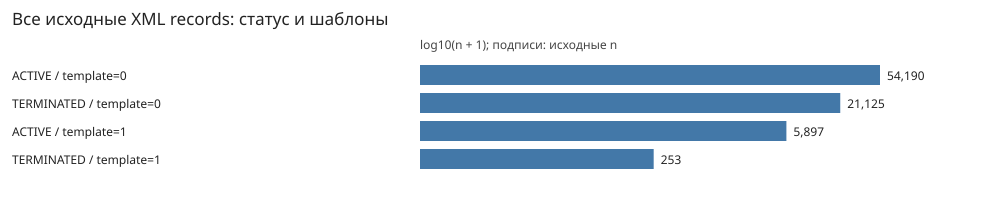

Отобрано по статусу, шаблону и application interval: 51332


In [5]:
tables = ["ktru_record", "ktru_code", "ktru_selected", "ktru_characteristic", "ktru_value", "ktru_numeric_atom", "ktru_classifier", "ktru_classifier_value", "data_issue"]
counts = pd.DataFrame([(table, conn.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]) for table in tables], columns=["table", "n"])
display(counts)
display(q("SELECT representation,COUNT(*) n FROM ktru_value GROUP BY representation"))
status = q("SELECT status || ' / template=' || COALESCE(is_template,'NULL') label,COUNT(*) n FROM ktru_record GROUP BY status,is_template ORDER BY n DESC")
bars(status, "label", "n", "Все исходные XML records: статус и шаблоны", log=True)
print("Отобрано по статусу, шаблону и application interval:", len(eligible_records(conn, AS_OF)))

### Версии и конфликтующие коды

Выбор наибольшей версии в этой snapshot является политикой импорта, а не утверждением, что snapshot содержит полную историю. Если новая версия ещё не действует, reference matcher не откатывается автоматически к старой: такая логика требует истории и отдельно проверенного правила.

Payload hash основан на XML C14N блока data. Он консервативен: различие namespace/prefix context может дать конфликт даже у семантически одинаковых записей. Ни один конфликт не разрешается по порядку файлов.

Отказ от версий означает latest-only projection, а не удаление номера версии из source. В текущей snapshot нет ни одного кода с несколькими version numbers: non-latest records отсутствуют. Конфликт одинаковой версии не разрешается правилом latest. Operational parent join игнорирует referenced version, но audit явно показывает, какие references не подтверждены текущей snapshot.

duplicate_codes.csv: 4 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/duplicate_codes.csv


,code,version,name,status,path,ordinal,payload_sha256
0,32.50.13.110-03169,2,Шприц инсулиновый/неубираемая игла,TERMINATED,/Users/paul/Projects/hackathon-tenderhack-kaza...,429,415009055abe23aabf4fc8fa8872db84802dfb94ff84d8...
1,32.50.13.110-03169,2,"Шприц общего назначения, одноразового использо...",TERMINATED,/Users/paul/Projects/hackathon-tenderhack-kaza...,472,c0fdf348148473f5d2cfc4c07e243964234aff35f260b4...
2,32.50.13.110-03170,2,Шприц инсулиновый/неубираемая игла,TERMINATED,/Users/paul/Projects/hackathon-tenderhack-kaza...,428,9800132d07058c6ccd2317cd77649b56753ef51b88049c...
3,32.50.13.110-03170,2,"Шприц общего назначения, одноразового использо...",TERMINATED,/Users/paul/Projects/hackathon-tenderhack-kaza...,470,7e76669a56da17dafa3e0eede9e2d7248f28930a8eaced...


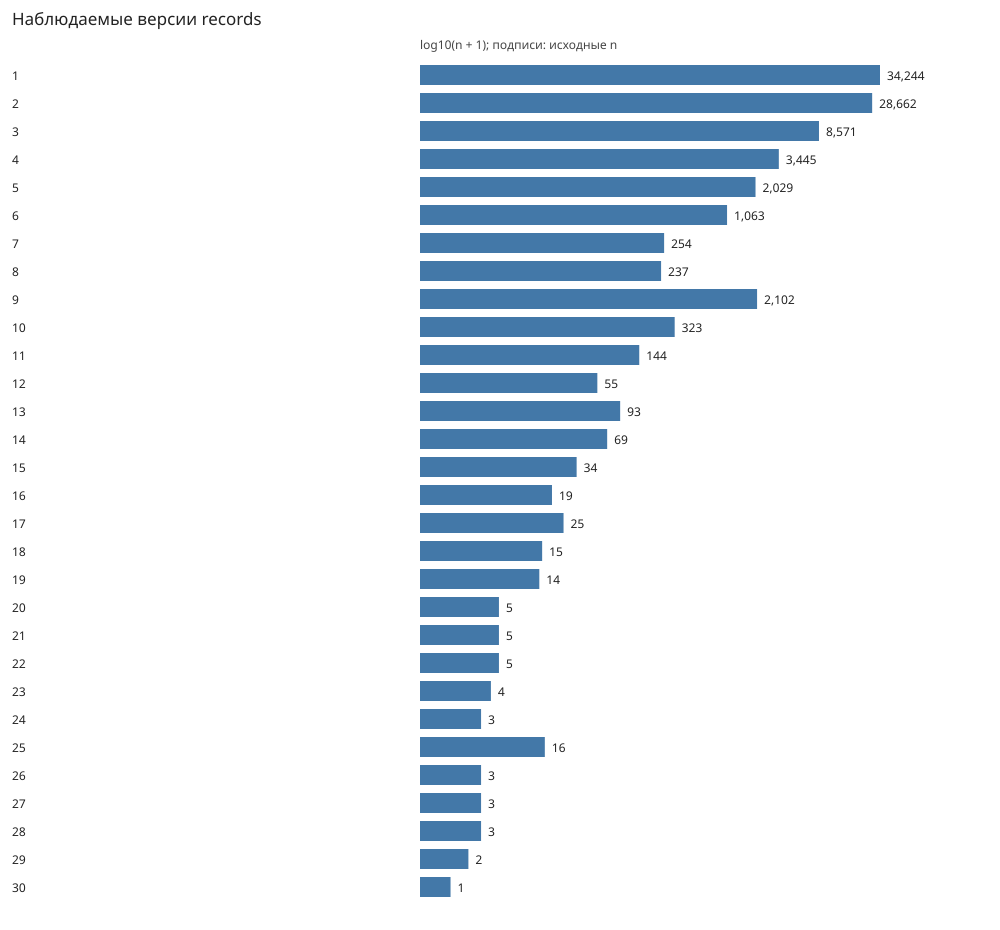

,code,versions,names
0,32.50.13.110-03169,1,2
1,32.50.13.110-03170,1,2


In [6]:
duplicates = q("""SELECT r.code,r.version,r.name,r.status,f.path,r.ordinal,r.payload_sha256
FROM ktru_record r JOIN xml_source_file f ON f.id=r.source_id
WHERE r.code IN (SELECT code FROM ktru_record GROUP BY code HAVING COUNT(*)>1)
ORDER BY r.code,r.version,f.path,r.ordinal""")
evidence("duplicate_codes.csv", duplicates)
version_distribution = q("SELECT version,COUNT(*) n FROM ktru_record GROUP BY version ORDER BY version")
bars(version_distribution, "version", "n", "Наблюдаемые версии records", limit=30, log=True)
display(q("SELECT code,COUNT(DISTINCT version) versions,COUNT(DISTINCT name) names FROM ktru_record GROUP BY code HAVING versions>1 OR names>1"))

## 4. Структурные исключения и иерархия

Код родителя, версия родителя и пригодность родителя для поиска проверяются отдельно. Не наследуем автоматически характеристики шаблона: несовпадение версий и допустимых значений делает такое наследование недоказанным.

В production-facing модели родителя разрешаем только по коду среди selected records. Strict `(code, version)` join ниже нужен для диагностики потери связи, не для построения иерархии.

In [7]:
checks = q("""
SELECT 'code starts with OKPD2' check_name,COUNT(*) denominator,
 SUM(CASE WHEN okpd2_code IS NOT NULL AND code LIKE okpd2_code || '%' THEN 1 ELSE 0 END) passed FROM ktru_record
UNION ALL SELECT 'TERMINATED iff cancelInfo',COUNT(*),SUM((status='TERMINATED')=has_cancel) FROM ktru_record
UNION ALL SELECT 'parent code resolves',COUNT(*),SUM(EXISTS(SELECT 1 FROM ktru_record p WHERE p.code=r.parent_code)) FROM ktru_record r WHERE parent_code IS NOT NULL
UNION ALL SELECT 'parent exact version resolves',COUNT(*),SUM(EXISTS(SELECT 1 FROM ktru_record p WHERE p.code=r.parent_code AND p.version=r.parent_version)) FROM ktru_record r WHERE parent_code IS NOT NULL
""")
checks["failed"] = checks.denominator - checks.passed
display(checks)
parent_exceptions = q("""SELECT r.code,r.version,r.parent_code,r.parent_version,
CASE WHEN NOT EXISTS(SELECT 1 FROM ktru_record p WHERE p.code=r.parent_code) THEN 'missing_code' ELSE 'missing_version' END reason
FROM ktru_record r WHERE r.parent_code IS NOT NULL AND NOT EXISTS
(SELECT 1 FROM ktru_record p WHERE p.code=r.parent_code AND p.version=r.parent_version)""")
evidence("parent_reference_exceptions.csv", parent_exceptions)
cancel_exceptions = q("SELECT code,version,status,has_cancel,cancel_date,cancel_reason FROM ktru_record WHERE (status='TERMINATED')<>has_cancel")
evidence("cancel_exceptions.csv", cancel_exceptions)
classifier_sizes = q("""SELECT c.record_id,c.id,c.nsi_code,COUNT(v.ordinal) n FROM ktru_classifier c
LEFT JOIN ktru_classifier_value v ON v.classifier_id=c.id GROUP BY c.id""")
display(classifier_sizes.groupby("nsi_code").agg(classifiers=("id","size"), multiple_values=("n",lambda x:(x>1).sum()), maximum=("n","max")))
extra_okpd = q("""SELECT r.code,r.okpd2_code,v.code classifier_okpd2,v.name
FROM ktru_classifier c JOIN ktru_record r ON r.id=c.record_id JOIN ktru_classifier_value v ON v.classifier_id=c.id
WHERE c.nsi_code='nsiOKPD2' AND v.code<>r.okpd2_code""")
evidence("additional_classifier_okpd2.csv", extra_okpd)

,check_name,denominator,passed,failed
0,code starts with OKPD2,81465,81465,0
1,TERMINATED iff cancelInfo,81465,81454,11
2,parent code resolves,64850,64850,0
3,parent exact version resolves,64850,43388,21462


parent_reference_exceptions.csv: 21,462 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/parent_reference_exceptions.csv


,code,version,parent_code,parent_version,reason
0,32.50.21.121-00004,2,32.50.21.121-00003,1,missing_version
1,32.50.21.121-00001,2,32.50.21.121-00003,1,missing_version
2,32.50.13.190-00080,2,32.50.13.190-00020,1,missing_version
3,32.50.13.190-00081,2,32.50.13.190-00020,1,missing_version
4,32.50.13.190-00078,2,32.50.13.190-00020,1,missing_version
5,32.50.13.190-00079,2,32.50.13.190-00020,1,missing_version
6,32.50.13.190-00049,5,32.50.13.190-00018,4,missing_version
7,32.50.13.190-00045,5,32.50.13.190-00018,4,missing_version
8,32.50.13.190-00046,5,32.50.13.190-00018,4,missing_version
9,32.50.13.190-00047,5,32.50.13.190-00018,4,missing_version


cancel_exceptions.csv: 11 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/cancel_exceptions.csv


,code,version,status,has_cancel,cancel_date,cancel_reason
0,32.50.50.000-00048,3,TERMINATED,0,None,None
1,20.59.52.140-00000154,2,TERMINATED,0,None,None
2,21.20.23.110-00007827,2,TERMINATED,0,None,None
3,32.50.13.190-00007042,2,TERMINATED,0,None,None
4,21.20.24.131-00000001,2,TERMINATED,0,None,None
5,32.50.30.110-00000020,2,TERMINATED,0,None,None
6,26.60.11.114-00000009,2,TERMINATED,0,None,None
7,32.50.50.190-00001166,2,TERMINATED,0,None,None
8,26.60.13.150-00000015,2,TERMINATED,0,None,None
9,32.50.12.000-00000016,2,TERMINATED,0,None,None


,classifiers,multiple_values,maximum
nsi_code,,,
nsiManualClassifier,1473,531,156
nsiNKMI,56700,2061,16
nsiOKPD2,80967,19248,24


additional_classifier_okpd2.csv: 36,685 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/additional_classifier_okpd2.csv


,code,okpd2_code,classifier_okpd2,name
0,32.50.21.121-00003,32.50.21.121,32.50.13.190,"Инструменты и приспособления, применяемые в ме..."
1,32.50.21.121-00004,32.50.21.121,32.50.13.190,"Инструменты и приспособления, применяемые в ме..."
2,32.50.21.121-00001,32.50.21.121,32.50.13.190,"Инструменты и приспособления, применяемые в ме..."
3,32.50.21.121-00002,32.50.21.121,32.50.13.190,"Инструменты и приспособления, применяемые в ме..."
4,32.50.13.190-00018,32.50.13.190,32.50.21.129,"Оборудование дыхательное прочее, не включенное..."
5,32.50.13.190-00018,32.50.13.190,32.50.21.121,Аппараты для ингаляционного наркоза
6,32.50.13.190-00018,32.50.13.190,32.50.21.123,Анестезиологические и респираторные медицински...
7,32.50.13.190-00018,32.50.13.190,32.50.21.122,Аппараты дыхательные реанимационные
8,32.50.13.190-00049,32.50.13.190,32.50.21.129,"Оборудование дыхательное прочее, не включенное..."
9,32.50.13.190-00049,32.50.13.190,32.50.21.121,Аппараты для ингаляционного наркоза


Циклы selected code graph: []


,depth,codes
0,1,64826
1,0,16615
2,2,20


largest_parent_families.csv: 5,958 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/largest_parent_families.csv


,code,name,status,children
0,32.50.22.190-00005485,"Протез твердой мозговой оболочки, синтетический",ACTIVE,1988
1,32.50.22.129-00000114,Пластина для фиксации для черепно-лицевой хиру...,ACTIVE,1764
2,32.50.13.190-06772,Окклюдер кардиологический (для закрытия открыт...,ACTIVE,1650
3,32.50.13.110-00003280,"Игла спинальная, одноразового использования",ACTIVE,1260
4,32.50.23.000-00000026,Компонент эндопротеза коленного сустава тибиал...,TERMINATED,1200
5,32.50.22.190-00003,Стент мочеточниковый полимерный,ACTIVE,1156
6,32.50.13.190-03992,Окклюдер кардиологический (для закрытия дефект...,ACTIVE,840
7,32.50.13.110-02380,Катетер баллонный для ангиопластики перифериче...,ACTIVE,792
8,32.50.13.190-02751,Окклюдер кардиологический (для закрытия дефект...,ACTIVE,784
9,32.50.22.190-02325,Сегмент интракорнеальный кольцевой,ACTIVE,768


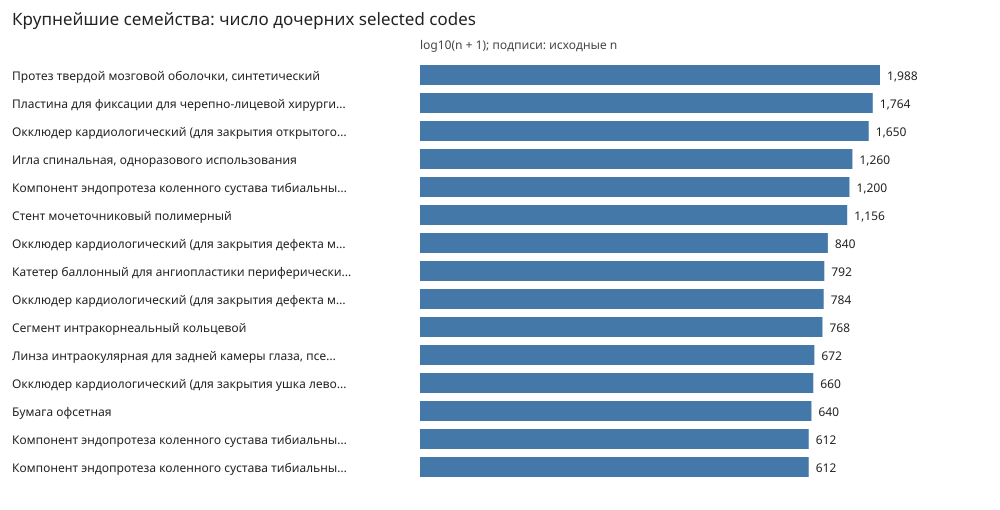

In [8]:
parents = dict(conn.execute("SELECT code,parent_code FROM ktru_selected"))
cycles, depths = [], {}
for start in parents:
    if start in depths:
        continue
    trail, seen, node = [], {}, start
    while node in parents and node not in depths and node not in seen:
        seen[node] = len(trail)
        trail.append(node)
        node = parents[node]
    if node in seen:
        cycles.append(trail[seen[node]:])
        for item in trail:
            depths[item] = None
    else:
        depth = depths.get(node, -1)
        for item in reversed(trail):
            depth = depth + 1 if depth is not None else None
            depths[item] = depth
print("Циклы selected code graph:", cycles)
display(pd.Series(list(depths.values()), dtype="Int64").value_counts(dropna=False).rename_axis("depth").reset_index(name="codes"))
parent_sizes = q("""SELECT p.code,p.name,p.status,COUNT(c.id) children
FROM ktru_selected p JOIN ktru_selected c ON c.parent_code=p.code GROUP BY p.id ORDER BY children DESC""")
evidence("largest_parent_families.csv", parent_sizes)
bars(parent_sizes, "name", "children", "Крупнейшие семейства: число дочерних selected codes", limit=15, log=True)

### Контрольная группа: точное совпадение указанной версии

Сравнение выполняется только там, где версия parent reference совпадает с selected parent. Отдельно считаем отсутствующую версию выше. Различие ID значения не означает различия значения; различие точных option signatures не означает несовместимости диапазонов. Subset здесь означает наличие той же option signature, а не геометрическое включение диапазона в другой.

Сравниваем определения целиком, включая actual=false, чтобы не скрыть изменения actuality. Коды характеристик сопоставляются в рамках пары, а изменения имени/type/units/kind/choice/required/actual показываются отдельно. Такое сравнение ещё не разрешает семантическую унификацию разных source codes.

Это baseline exact-version группа. Следующий раздел сравнивает **все** latest-only code-resolved связи, в том числе references на отсутствующие версии, не исключая их молча.

In [9]:
from catalogue_audit import parent_agreement
agreement = parent_agreement(conn)
display(pd.DataFrame([
    ("exact-version pairs",len(agreement)),
    ("same characteristic code sets",agreement.characteristic_code_sets_equal.sum()),
    ("child characteristic extensions",(agreement.child_chars_absent_parent>0).sum()),
    ("child value ID differences",(agreement.child_value_ids_absent_parent>0).sum()),
    ("exact option signature differences",(agreement.child_exact_option_signatures_absent_parent>0).sum()),
    ("metadata differences",(agreement.metadata_mismatches>0).sum()),
    ("ambiguous pairs",agreement.ambiguous.sum()),
],columns=["measure","pairs"]))
evidence("parent_child_agreement.csv",agreement[agreement.is_outlier])

,measure,pairs
0,exact-version pairs,43388
1,same characteristic code sets,37445
2,child characteristic extensions,1696
3,child value ID differences,29586
4,exact option signature differences,1749
5,metadata differences,22
6,ambiguous pairs,4


parent_child_agreement.csv: 31,526 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/parent_child_agreement.csv


,child_record_id,parent_record_id,child_code,parent_code,characteristic_code_sets_equal,child_chars_absent_parent,child_value_ids_absent_parent,child_exact_option_signatures_absent_parent,metadata_mismatches,duplicate_source_char_codes,...,child_semantic_options,child_semantic_options_absent_parent,child_names_absent_parent_examples,semantic_option_feature_examples,child_actual_names,child_actual_names_absent_parent,child_actual_options,child_actual_options_absent_parent,child_actual_names_absent_parent_examples,actual_option_feature_examples
0,12,11,32.50.21.121-00002,32.50.13.190-00019,False,0,0,0,0,0,...,0,0,,,0,0,0,0,,
1,31,30,32.50.13.190-00052,32.50.13.190-00015,True,0,1,0,0,0,...,1,0,,,1,0,1,0,,
2,32,30,32.50.13.190-00050,32.50.13.190-00015,True,0,1,0,0,0,...,1,0,,,1,0,1,0,,
3,33,30,32.50.13.190-00051,32.50.13.190-00015,True,0,1,0,0,0,...,1,0,,,1,0,1,0,,
4,37,36,32.50.13.190-00053,32.50.13.190-00011,True,0,1,0,0,0,...,1,0,,,1,0,1,0,,
7,43,39,32.50.21.129-00002,32.50.21.129-00001,False,0,0,0,0,0,...,5,0,,,5,0,5,0,,
8,47,44,32.50.13.190-00069,32.50.13.190-00010,True,0,2,0,0,0,...,2,0,,,2,0,2,0,,
9,48,44,32.50.13.190-00067,32.50.13.190-00010,True,0,2,0,0,0,...,2,0,,,2,0,2,0,,
10,49,44,32.50.13.190-00068,32.50.13.190-00010,True,0,2,0,0,0,...,2,0,,,2,0,2,0,,
11,50,44,32.50.13.190-00065,32.50.13.190-00010,True,0,2,0,0,0,...,2,0,,,2,0,2,0,,


### Latest-only: отсутствующие версии, потерянные links и существенные различия

Разделяем три события:

1. `referenced_version_missing`: указанной пары parent code/version нет **ни в одном исходном record** snapshot.
2. `dropped_by_strict_latest_version`: strict version join latest-only таблиц потерял бы связь. `code_only_rebound` показывает связи, которые сохраняются, если разрешать parent только по коду.
3. `dropped_by_code_only`: даже code-only join не даёт selected parent. Это может означать отсутствующий код или конфликт на его последней версии; нельзя маскировать это как «всё разрешилось».

`large_difference_review` сравнивает child с latest parent: не менее **3** отсутствующих актуальных нормализованных имён **или** точных options, составляющих не менее **50%** соответствующего child set. Имена сохраняют min/max; сравнение options не зависит от valueCode и characteristicCode. Неактуальные определения отражены в отдельных общих счётчиках, но не запускают поисковый review flag. Ambiguous definitions дают NULL, не «нет различий».

Это прозрачный порог очереди на review, не доказательство несовместимости. Дочерняя option может быть narrower range внутри parent range, иметь другую размерность/unit spelling или semantic alias. Проверка exact signatures не выполняет numerical interval containment или conversion. Сужение характеристик шаблона потомком ожидаемо; отсутствие лишних **parent** options не запускает этот directional flag.

Если referenced version отсутствует, изменение **старого parent относительно latest parent** узнать невозможно. `historical_comparison_state` явно сообщает `referenced_version_absent_change_unmeasurable`, а исторический difference flag остаётся NULL. Если такая старая версия есть и не конфликтует, её сравниваем с latest отдельно в `referenced_vs_latest_*` columns.


,raw_records,selected_latest_records,nonlatest_records,codes_with_multiple_versions
0,81465,81461,0,0


versions_missing_from_snapshot.csv: 914 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/versions_missing_from_snapshot.csv


,parent_code,referenced_parent_version,raw_child_references,child_codes,latest_observed_parent_version,parent_code_in_snapshot,latest_parent_selected
0,32.50.22.190-00005485,1,1984,1984,4,1,1
1,32.50.23.000-00000026,1,1200,1200,2,1,1
2,32.50.22.190-00003,2,1078,1078,12,1,1
3,32.50.22.190-02325,1,712,712,2,1,1
4,17.12.14.112-00000001,2,637,637,5,1,1
5,32.50.13.120-00822,1,624,624,6,1,1
6,32.50.22.110-00001016,1,612,612,2,1,1
7,58.11.11.000-00000436,1,541,541,2,1,1
8,26.51.51.110-00000002,2,419,419,8,1,1
9,32.50.13.190-01445,1,419,419,3,1,1


Отсутствующих уникальных parent code/version pairs: 914 ; raw references: 21462


,parent_references,referenced_version_missing,dropped_by_strict_latest_version,dropped_by_code_only,retained_by_code_only_rebinding,rebound_large_difference_review,rebound_difference_unknown
all_selected,64847,21459,21459,1,21458,8778,1
search_eligible_children,45166,2180,2180,0,2180,796,0


...

latest_parent_unresolved.csv: 1 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/latest_parent_unresolved.csv


,child_record_id,child_code,child_version,parent_code,referenced_parent_version,parent_record_id,latest_parent_version,parent_code_in_snapshot,referenced_version_in_snapshot,referenced_version_missing,...,referenced_vs_latest_large_difference_review,child_name,child_status,child_is_template,child_application_start,child_application_end,latest_parent_name,latest_parent_status,latest_parent_is_template,child_search_eligible
7329,7430,32.50.13.110-03168,2,32.50.13.110-03170,1,NaN,NaN,1,0,1,...,<NA>,Шприц инсулиновый/неубираемая игла,TERMINATED,0,2018-03-01T00:00:00+03:00,NaN,NaN,NaN,NaN,False


rebound_parent_large_differences.csv: 8,778 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/rebound_parent_large_differences.csv


,child_record_id,child_code,child_version,parent_code,referenced_parent_version,parent_record_id,latest_parent_version,parent_code_in_snapshot,referenced_version_in_snapshot,referenced_version_missing,...,referenced_vs_latest_large_difference_review,child_name,child_status,child_is_template,child_application_start,child_application_end,latest_parent_name,latest_parent_status,latest_parent_is_template,child_search_eligible
16745,16926,26.20.15.000-00000041,3,26.20.15.000-00000032,2,16256.0,28.0,1,0,1,...,<NA>,Компьютер персональный настольный (моноблок),TERMINATED,0,2019-08-01T00:00:00+03:00,NaN,Компьютер персональный настольный (моноблок),ACTIVE,1.0,False
16746,16927,26.20.15.000-00000040,3,26.20.15.000-00000032,2,16256.0,28.0,1,0,1,...,<NA>,Компьютер персональный настольный (моноблок),TERMINATED,0,2019-08-01T00:00:00+03:00,NaN,Компьютер персональный настольный (моноблок),ACTIVE,1.0,False
17029,17242,26.20.15.000-00000033,3,26.20.15.000-00000032,2,16256.0,28.0,1,0,1,...,<NA>,Компьютер персональный настольный (моноблок),TERMINATED,0,2019-08-01T00:00:00+03:00,NaN,Компьютер персональный настольный (моноблок),ACTIVE,1.0,False
47130,58125,26.20.15.000-00000433,2,26.20.15.000-00000032,2,16256.0,28.0,1,0,1,...,<NA>,Компьютер персональный настольный (моноблок),TERMINATED,0,2019-08-01T00:00:00+03:00,NaN,Компьютер персональный настольный (моноблок),ACTIVE,1.0,False
116,174,32.50.13.190-00042,2,32.50.13.190-00014,1,34.0,3.0,1,0,1,...,<NA>,Набор для переливания крови,TERMINATED,0,2018-01-01T00:00:00+03:00,NaN,"Комплект для переливания крови, не обменный",ACTIVE,1.0,False
117,175,32.50.13.190-00041,2,32.50.13.190-00014,1,34.0,3.0,1,0,1,...,<NA>,Набор для переливания крови,TERMINATED,0,2018-01-01T00:00:00+03:00,NaN,"Комплект для переливания крови, не обменный",ACTIVE,1.0,False
120,178,32.50.13.190-00040,2,32.50.13.190-00014,1,34.0,3.0,1,0,1,...,<NA>,Набор для переливания крови,TERMINATED,0,2018-01-01T00:00:00+03:00,NaN,"Комплект для переливания крови, не обменный",ACTIVE,1.0,False
122,180,32.50.13.190-00039,2,32.50.13.190-00014,1,34.0,3.0,1,0,1,...,<NA>,Набор для переливания крови,TERMINATED,0,2018-01-01T00:00:00+03:00,NaN,"Комплект для переливания крови, не обменный",ACTIVE,1.0,False
125,183,32.50.13.190-00038,2,32.50.13.190-00014,1,34.0,3.0,1,0,1,...,<NA>,Набор для переливания крови,TERMINATED,0,2018-01-01T00:00:00+03:00,NaN,"Комплект для переливания крови, не обменный",ACTIVE,1.0,False
128,186,32.50.13.190-00037,2,32.50.13.190-00014,1,34.0,3.0,1,0,1,...,<NA>,Набор для переливания крови,TERMINATED,0,2018-01-01T00:00:00+03:00,NaN,"Комплект для переливания крови, не обменный",ACTIVE,1.0,False


,child_code,child_name,parent_code,referenced_parent_version,latest_parent_version,child_actual_names,child_actual_names_absent_parent,actual_name_missing_share,child_actual_options,child_actual_options_absent_parent,actual_option_missing_share,child_actual_names_absent_parent_examples,actual_option_feature_examples,difference_flag_reason
16745,26.20.15.000-00000041,Компьютер персональный настольный (моноблок),26.20.15.000-00000032,2,28.0,8.0,8.0,1.0,92.0,92.0,1.0,вид накопителя | максимальный размер диагонали...,вид накопителя | максимальный размер диагонали...,at_least_3_and_50pct_actual_child_names_absent...
16746,26.20.15.000-00000040,Компьютер персональный настольный (моноблок),26.20.15.000-00000032,2,28.0,8.0,8.0,1.0,92.0,92.0,1.0,вид накопителя | максимальный размер диагонали...,вид накопителя | максимальный размер диагонали...,at_least_3_and_50pct_actual_child_names_absent...
17029,26.20.15.000-00000033,Компьютер персональный настольный (моноблок),26.20.15.000-00000032,2,28.0,8.0,8.0,1.0,92.0,92.0,1.0,вид накопителя | максимальный размер диагонали...,вид накопителя | максимальный размер диагонали...,at_least_3_and_50pct_actual_child_names_absent...
47130,26.20.15.000-00000433,Компьютер персональный настольный (моноблок),26.20.15.000-00000032,2,28.0,8.0,8.0,1.0,92.0,92.0,1.0,вид накопителя | максимальный размер диагонали...,вид накопителя | максимальный размер диагонали...,at_least_3_and_50pct_actual_child_names_absent...
116,32.50.13.190-00042,Набор для переливания крови,32.50.13.190-00014,1,3.0,7.0,7.0,1.0,7.0,7.0,1.0,диаметр инъекционной иглы | длина соединительн...,диаметр инъекционной иглы | длина соединительн...,at_least_3_and_50pct_actual_child_names_absent...
117,32.50.13.190-00041,Набор для переливания крови,32.50.13.190-00014,1,3.0,7.0,7.0,1.0,7.0,7.0,1.0,диаметр инъекционной иглы | длина соединительн...,диаметр инъекционной иглы | длина соединительн...,at_least_3_and_50pct_actual_child_names_absent...
120,32.50.13.190-00040,Набор для переливания крови,32.50.13.190-00014,1,3.0,7.0,7.0,1.0,7.0,7.0,1.0,диаметр инъекционной иглы | длина соединительн...,диаметр инъекционной иглы | длина соединительн...,at_least_3_and_50pct_actual_child_names_absent...
122,32.50.13.190-00039,Набор для переливания крови,32.50.13.190-00014,1,3.0,7.0,7.0,1.0,7.0,7.0,1.0,диаметр инъекционной иглы | длина соединительн...,диаметр инъекционной иглы | длина соединительн...,at_least_3_and_50pct_actual_child_names_absent...
125,32.50.13.190-00038,Набор для переливания крови,32.50.13.190-00014,1,3.0,7.0,7.0,1.0,7.0,7.0,1.0,диаметр инъекционной иглы | длина соединительн...,диаметр инъекционной иглы | длина соединительн...,at_least_3_and_50pct_actual_child_names_absent...
128,32.50.13.190-00037,Набор для переливания крови,32.50.13.190-00014,1,3.0,7.0,7.0,1.0,7.0,7.0,1.0,диаметр инъекционной иглы | длина соединительн...,диаметр инъекционной иглы | длина соединительн...,at_least_3_and_50pct_actual_child_names_absent...


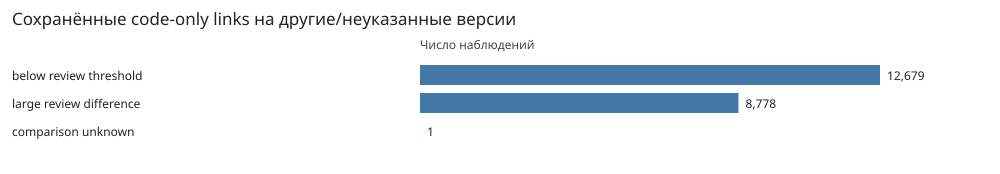

Наличие code-only link не разрешает наследовать характеристики latest parent без проверки.


In [10]:
from catalogue_audit import parent_latest_audit

version_projection = q("""SELECT
 (SELECT COUNT(*) FROM ktru_record) raw_records,
 (SELECT COUNT(*) FROM ktru_selected) selected_latest_records,
 (SELECT COUNT(*) FROM ktru_record r WHERE r.version <
    (SELECT MAX(s.version) FROM ktru_record s WHERE s.code=r.code)) nonlatest_records,
 (SELECT COUNT(*) FROM (SELECT code FROM ktru_record GROUP BY code HAVING COUNT(DISTINCT version)>1)) codes_with_multiple_versions
""")
display(version_projection)

missing_versions = q("""SELECT r.parent_code,r.parent_version referenced_parent_version,
COUNT(*) raw_child_references,COUNT(DISTINCT r.code) child_codes,
(SELECT MAX(p.version) FROM ktru_record p WHERE p.code=r.parent_code) latest_observed_parent_version,
EXISTS(SELECT 1 FROM ktru_record p WHERE p.code=r.parent_code) parent_code_in_snapshot,
EXISTS(SELECT 1 FROM ktru_selected p WHERE p.code=r.parent_code) latest_parent_selected
FROM ktru_record r WHERE r.parent_code IS NOT NULL AND r.parent_version IS NOT NULL
AND NOT EXISTS(SELECT 1 FROM ktru_record p WHERE p.code=r.parent_code AND p.version=r.parent_version)
GROUP BY r.parent_code,r.parent_version ORDER BY raw_child_references DESC,r.parent_code""")
evidence("versions_missing_from_snapshot.csv",missing_versions)
print("Отсутствующих уникальных parent code/version pairs:",len(missing_versions),
      "; raw references:",int(missing_versions.raw_child_references.sum()))

latest_relations = parent_latest_audit(conn)
record_labels = q("SELECT id,name,status,is_template,application_start,application_end FROM ktru_record")
latest_relations = latest_relations.merge(record_labels.rename(columns={
    "id":"child_record_id","name":"child_name","status":"child_status",
    "is_template":"child_is_template","application_start":"child_application_start","application_end":"child_application_end",
}),on="child_record_id",how="left")
latest_relations = latest_relations.merge(record_labels[["id","name","status","is_template"]].rename(columns={
    "id":"parent_record_id","name":"latest_parent_name","status":"latest_parent_status","is_template":"latest_parent_is_template",
}),on="parent_record_id",how="left")
latest_relations["child_search_eligible"] = latest_relations.child_record_id.isin({i for i,_ in eligible_records(conn,AS_OF)})

def relation_summary(group):
    return pd.Series({
        "parent_references":len(group),
        "referenced_version_missing":int(group.referenced_version_missing.sum()),
        "dropped_by_strict_latest_version":int(group.dropped_by_strict_latest_version.sum()),
        "dropped_by_code_only":int(group.dropped_by_code_only.sum()),
        "retained_by_code_only_rebinding":int(group.code_only_rebound.sum()),
        "rebound_large_difference_review":int(group.code_only_rebound_large_difference.sum()),
        "rebound_difference_unknown":int((group.code_only_rebound.eq(1)&group.large_difference_review.isna()).sum()),
    })
display(pd.DataFrame({"all_selected":relation_summary(latest_relations),
                      "search_eligible_children":relation_summary(latest_relations[latest_relations.child_search_eligible])}).T)
display(latest_relations.historical_comparison_state.value_counts().rename_axis("historical_comparison_state").reset_index(name="relations"))
evidence("latest_parent_relations.csv",latest_relations)
evidence("latest_parent_unresolved.csv",latest_relations[latest_relations.dropped_by_code_only.eq(1)])

rebound = latest_relations[latest_relations.code_only_rebound.eq(1)].copy()
large = rebound[rebound.large_difference_review.fillna(False)].sort_values(
    ["actual_name_missing_share","actual_option_missing_share","child_actual_names"],ascending=False)
evidence("rebound_parent_large_differences.csv",large)
display(large[["child_code","child_name","parent_code","referenced_parent_version","latest_parent_version",
               "child_actual_names","child_actual_names_absent_parent","actual_name_missing_share",
               "child_actual_options","child_actual_options_absent_parent","actual_option_missing_share",
               "child_actual_names_absent_parent_examples","actual_option_feature_examples","difference_flag_reason"]].head(20))

flag_distribution = rebound.large_difference_review.map({True:"large review difference",False:"below review threshold"}).fillna("comparison unknown").value_counts().rename_axis("flag").reset_index(name="n")
bars(flag_distribution,"flag","n","Сохранённые code-only links на другие/неуказанные версии",limit=10)
print("Наличие code-only link не разрешает наследовать характеристики latest parent без проверки.")


## 5. Распределения и покрытие для поиска

Полная выгрузка и выбранные поисковые кандидаты имеют разные знаменатели. Префиксы из старого notebook оставлены только как диагностическая гипотеза области. В частности, `26.51` включает термометры, `14.*` включает услуги, а `15.1` включает кожевенную продукцию. Это не размеченная ground truth связь с категориями workbook.

,codes,eligible,no_actual_chars
heuristic_domain,,,
Инструменты,1768,761,100
Мебель,388,224,13
Одежда,1579,1020,125
вне ручной области,77726,49327,9502


eligible_without_actual_characteristics.csv: 5,391 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/eligible_without_actual_characteristics.csv


,id,code,name,status,is_template,okpd2_code,application_start,application_end,n_chars,n_actual,n_required,eligible,heuristic_domain
16237,16242,06.10.10.100-00000001,Нефть сырая,ACTIVE,0,06.10.10.100,2018-10-01T00:00:00+03:00,NaN,0,0,0,True,вне ручной области
16239,16244,06.20.10.110-00000001,Газ горючий природный компримированный,ACTIVE,0,06.20.10.110,2018-10-01T00:00:00+03:00,NaN,0,0,0,True,вне ручной области
16240,16245,06.20.10.131-00000001,Газ горючий природный сжиженный,ACTIVE,0,06.20.10.131,2018-10-01T00:00:00+03:00,NaN,0,0,0,True,вне ручной области
16242,16247,19.20.32.111-00000001,Этилен,ACTIVE,0,19.20.32.111,2018-10-01T00:00:00+03:00,NaN,0,0,0,True,вне ручной области
16243,16248,19.20.32.113-00000001,Бутилен,ACTIVE,0,19.20.32.113,2018-10-01T00:00:00+03:00,NaN,0,0,0,True,вне ручной области
16244,16249,19.20.32.112-00000001,Пропилен,ACTIVE,0,19.20.32.112,2018-10-01T00:00:00+03:00,NaN,0,0,0,True,вне ручной области
16245,16250,19.20.32.119-00000006,Фракция нормального бутана,ACTIVE,0,19.20.32.119,2018-10-01T00:00:00+03:00,NaN,0,0,0,True,вне ручной области
16246,16251,19.20.32.119-00000005,Бутан-бутиленовая фракция,ACTIVE,0,19.20.32.119,2018-10-01T00:00:00+03:00,NaN,0,0,0,True,вне ручной области
16247,16252,19.20.32.119-00000004,Изобутановая фракция,ACTIVE,0,19.20.32.119,2018-10-01T00:00:00+03:00,NaN,0,0,0,True,вне ручной области
16248,16253,19.20.32.119-00000003,Пропановая фракция,ACTIVE,0,19.20.32.119,2018-10-01T00:00:00+03:00,NaN,0,0,0,True,вне ручной области


,count,mean,std,min,50%,90%,95%,99%,max
n_chars,51332.0,3.878886,4.736706,0.0,3.0,7.0,9.0,17.0,205.0
n_actual,51332.0,3.878886,4.736706,0.0,3.0,7.0,9.0,17.0,205.0
n_required,51332.0,2.715733,2.019464,0.0,3.0,5.0,6.0,9.0,62.0


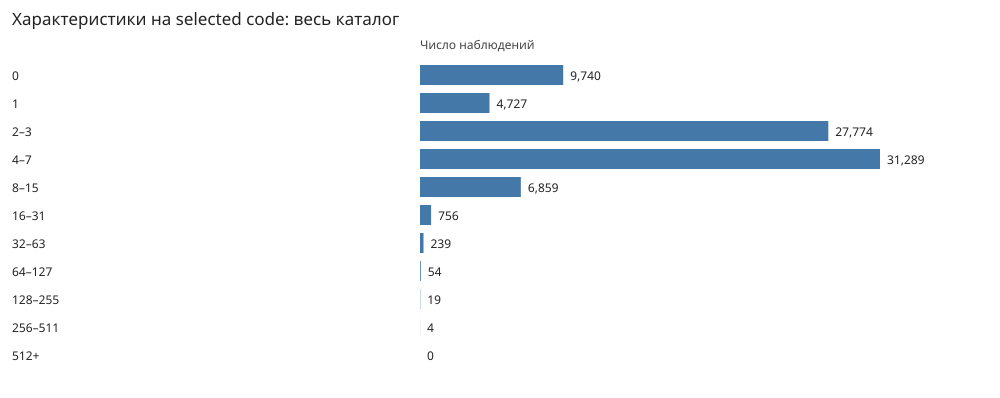

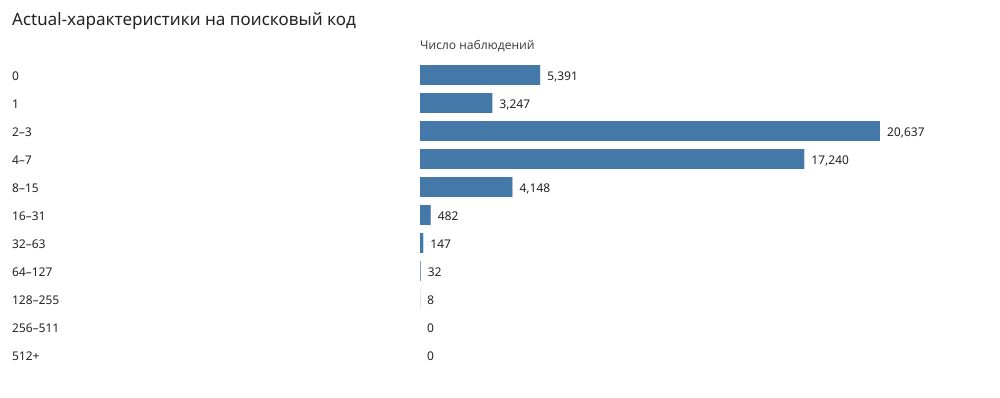

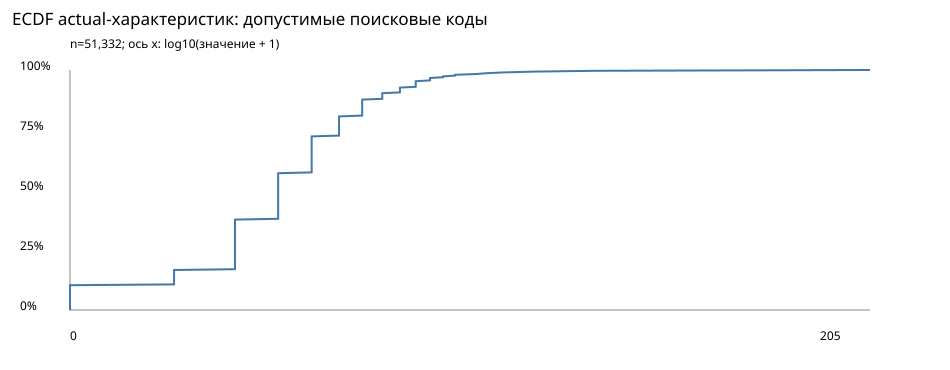

most_characteristics.csv: 81,461 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/most_characteristics.csv


,id,code,name,status,is_template,okpd2_code,application_start,application_end,n_chars,n_actual,n_required,eligible,heuristic_domain
69748,69753,26.30.11.110-00000052,Коммутатор,TERMINATED,0,26.30.11.110,2021-01-20T00:00:00+03:00,NaN,300,300,55,False,вне ручной области
17224,17229,26.30.11.110-00000001,Коммутатор,ACTIVE,1,26.30.11.110,2026-10-16T00:00:00+03:00,NaN,274,274,6,False,вне ручной области
17265,17270,26.30.11.110-00000041,Коммутатор,ACTIVE,0,26.30.11.110,2026-10-16T00:00:00+03:00,NaN,274,274,6,False,вне ручной области
73044,73049,26.30.11.110-00000053,Коммутатор,ACTIVE,0,26.30.11.110,2026-10-16T00:00:00+03:00,NaN,266,266,6,False,вне ручной области
67079,67084,26.60.12.132-00000036,Система ультразвуковой визуализации универсаль...,ACTIVE,0,26.60.12.132,2026-06-17T00:00:00+03:00,NaN,205,205,17,True,вне ручной области
67064,67069,26.60.12.132-00000037,Система ультразвуковой визуализации универсаль...,ACTIVE,1,26.60.12.132,2026-06-17T00:00:00+03:00,NaN,205,205,17,False,вне ручной области
17305,17310,26.30.11.120-00000001,Маршрутизатор,ACTIVE,1,26.30.11.120,2026-08-29T00:00:00+03:00,NaN,199,199,0,False,вне ручной области
17374,17379,26.30.11.120-00000002,Маршрутизатор,ACTIVE,0,26.30.11.120,2026-08-29T00:00:00+03:00,NaN,199,199,0,True,вне ручной области
63387,63392,26.60.11.119-00000028,Система рентгеновской компьютерной томографии ...,ACTIVE,1,26.60.11.119,2026-10-18T00:00:00+03:00,NaN,182,182,181,False,вне ручной области
75162,75167,26.40.31.190-00000030,Радиосистема,ACTIVE,1,26.40.31.190,2024-09-11T00:00:00+03:00,NaN,177,177,1,False,вне ручной области


In [11]:
POS = q("""SELECT r.id,r.code,r.name,r.status,r.is_template,r.okpd2_code,r.application_start,r.application_end,
COUNT(c.id) n_chars,SUM(CASE WHEN c.actual=1 THEN 1 ELSE 0 END) n_actual,
SUM(CASE WHEN c.actual=1 AND c.required=1 THEN 1 ELSE 0 END) n_required
FROM ktru_selected r LEFT JOIN ktru_characteristic c ON c.record_id=r.id GROUP BY r.id""")
eligible_ids = {record_id for record_id,_ in eligible_records(conn, AS_OF)}
POS["eligible"] = POS.id.isin(eligible_ids)
PREFIXES = {"Мебель": ("31.",), "Одежда": ("14.", "15.1", "15.2"), "Инструменты": ("25.7", "28.24", "26.51", "27.90")}
POS["heuristic_domain"] = POS.okpd2_code.map(lambda c: next((name for name,prefixes in PREFIXES.items() if c and c.startswith(prefixes)), "вне ручной области"))
display(POS.groupby("heuristic_domain").agg(codes=("code","size"), eligible=("eligible","sum"), no_actual_chars=("n_actual",lambda x:(x==0).sum())))
no_chars = POS[POS.eligible & (POS.n_actual == 0)]
evidence("eligible_without_actual_characteristics.csv", no_chars)
display(POS.loc[POS.eligible,["n_chars","n_actual","n_required"]].describe(percentiles=[.5,.9,.95,.99]).T)
bars(count_distribution(POS.n_chars), "bucket", "n", "Характеристики на selected code: весь каталог", limit=20)
bars(count_distribution(POS.loc[POS.eligible,"n_actual"]), "bucket", "n", "Actual-характеристики на поисковый код", limit=20)
ecdf(POS.loc[POS.eligible,"n_actual"], "ECDF actual-характеристик: допустимые поисковые коды")
evidence("most_characteristics.csv", POS.sort_values("n_chars",ascending=False))

okpd2_concentration.csv: 2,911 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/okpd2_concentration.csv


,okpd2_code,codes
0,21.20.23.110,11887
1,32.50.13.190,8812
2,32.50.13.110,5830
3,32.50.22.190,5490
4,32.50.23.000,4140
5,32.50.50.190,3106
6,32.50.22.129,2611
7,32.50.50.000,2455
8,32.50.22.110,2275
9,32.50.13.120,1391


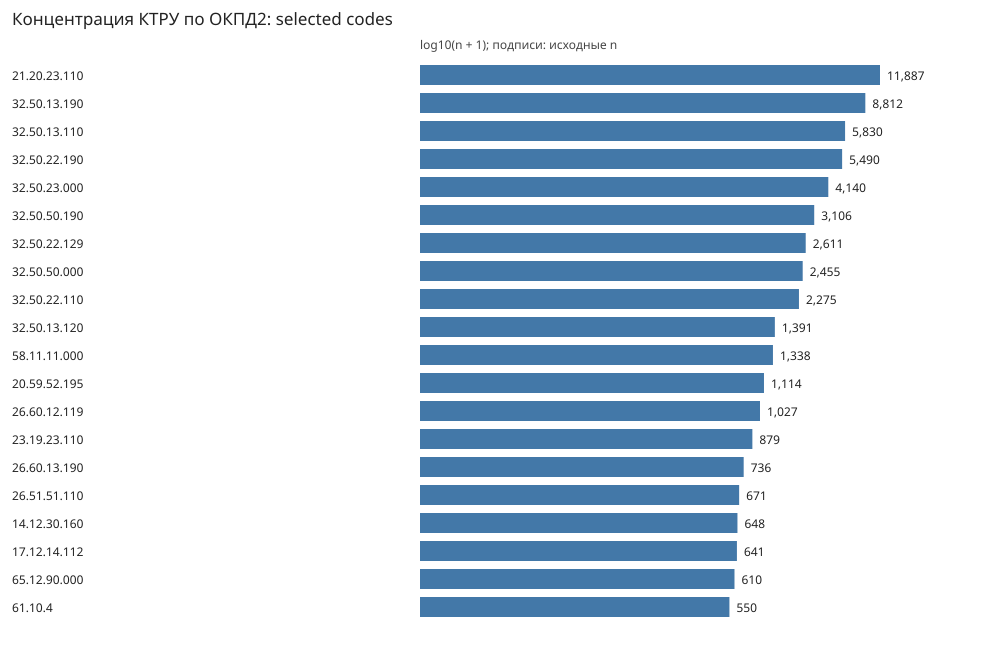

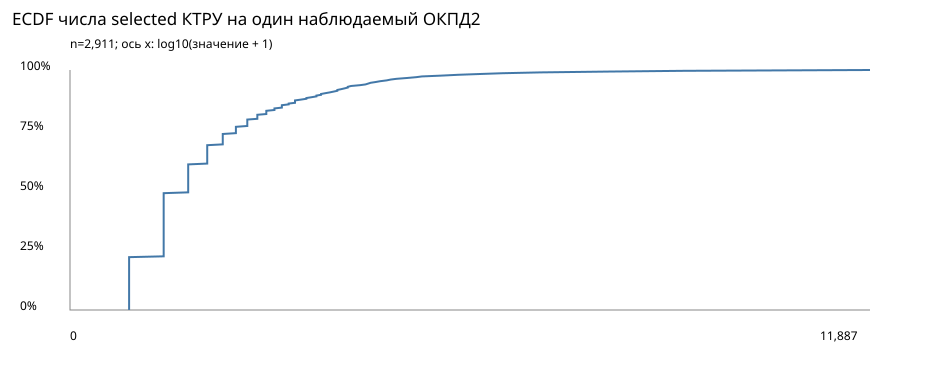

Доля 10 крупнейших ОКПД2: 0.5892021949153583
ОКПД2 с единственным кодом: 647 из 2911


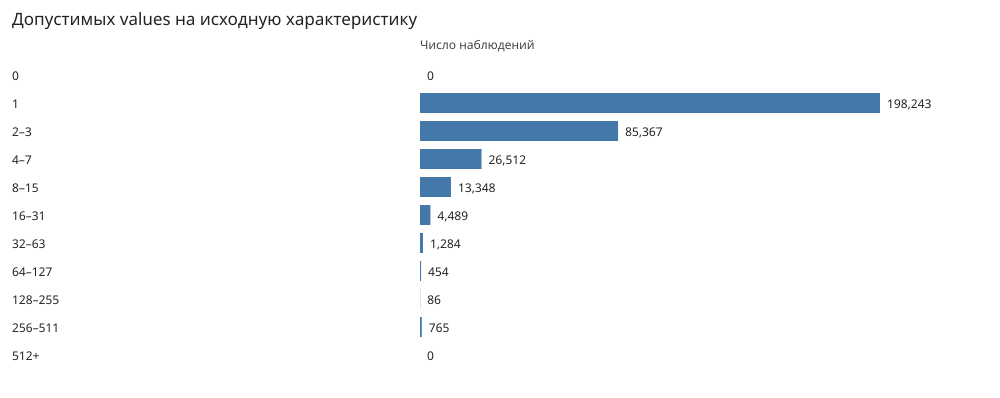

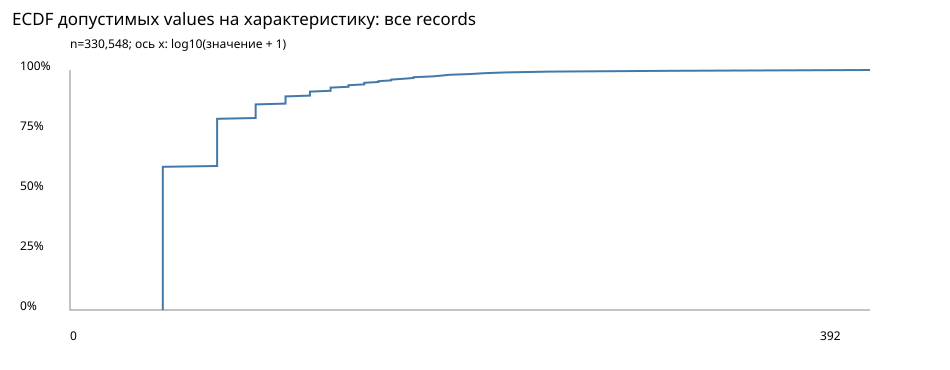

most_allowed_values.csv: 330,548 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/most_allowed_values.csv


,id,record_id,name,type,actual,n_values
281963,281964,71648,Наименование культуры,1,1,392
281957,281958,71647,Наименование культуры,1,1,392
264133,264134,68281,Номер профиля,1,1,358
270755,270756,69671,Номер двутавра,1,1,340
270743,270744,69670,Номер двутавра,1,1,340
91306,91307,24567,Автор/авторский коллектив,1,1,305
36206,36207,9446,"Диоптрийный ряд, дптр",2,1,281
36350,36351,9470,"Диоптрийный ряд, дптр",2,1,281
36134,36135,9431,"Диоптрийный ряд, дптр",2,1,281
36362,36363,9473,"Диоптрийный ряд, дптр",2,1,281


In [12]:
okpd_sizes = POS.groupby("okpd2_code",dropna=False).size().rename("codes").sort_values(ascending=False).reset_index()
evidence("okpd2_concentration.csv", okpd_sizes)
bars(okpd_sizes, "okpd2_code", "codes", "Концентрация КТРУ по ОКПД2: selected codes", limit=20, log=True)
ecdf(okpd_sizes.codes, "ECDF числа selected КТРУ на один наблюдаемый ОКПД2")
print("Доля 10 крупнейших ОКПД2:", okpd_sizes.codes.head(10).sum()/len(POS))
print("ОКПД2 с единственным кодом:", (okpd_sizes.codes==1).sum(), "из",len(okpd_sizes))
char_counts = q("""SELECT c.id,c.record_id,c.name,c.type,c.actual,COUNT(v.id) n_values
FROM ktru_characteristic c LEFT JOIN ktru_value v ON v.characteristic_id=c.id GROUP BY c.id""")
bars(count_distribution(char_counts.n_values), "bucket", "n", "Допустимых values на исходную характеристику", limit=20)
ecdf(char_counts.n_values, "ECDF допустимых values на характеристику: все records")
evidence("most_allowed_values.csv", char_counts.sort_values("n_values",ascending=False))

### Имена, типы и единицы: унификация ещё не доказана

Равное нормализованное имя служит кандидатным признаком для словаря, а не семантическим идентификатором. «Тип» зависит от товара; «Длина» может иметь разные типы и единицы; `min/max` остаются частью имени. «Качественные» значения иногда сами содержат числовой текст: исходный type не заменяет разбор семантики.

Единицы отсутствуют не только из-за дефектов: некоторые характеристики могут быть безразмерными. Но из отсутствия ОКЕИ это не следует. Reference matcher требует явной единицы, пока вручную не подтверждена безразмерность. Показываем обе частоты: по значениям и по определениям характеристик. Длинный список options сильно влияет на первую; вторая ближе к покрытию признаков. Ни одна из частот не является основанием для молчаливого назначения единицы.

In [13]:
name_conflicts = q("""SELECT name_norm,COUNT(DISTINCT source_code) source_codes,COUNT(DISTINCT type) types,
COUNT(DISTINCT record_id) records FROM ktru_characteristic GROUP BY name_norm ORDER BY records DESC""")
evidence("characteristic_name_profile.csv", name_conflicts)
evidence("names_with_multiple_types.csv", name_conflicts[name_conflicts.types>1])
code_conflicts = q("""SELECT source_code,COUNT(DISTINCT name) names,COUNT(DISTINCT type) types,
GROUP_CONCAT(DISTINCT name) examples FROM ktru_characteristic GROUP BY source_code HAVING names>1 OR types>1""")
evidence("characteristic_code_conflicts.csv", code_conflicts)
display(q("SELECT type,kind,choice_type,required,actual,COUNT(*) n FROM ktru_characteristic GROUP BY type,kind,choice_type,required,actual ORDER BY n DESC LIMIT 20"))
text_numbers = q("""SELECT r.code,c.name,v.quality_text FROM ktru_value v
JOIN ktru_characteristic c ON c.id=v.characteristic_id JOIN ktru_record r ON r.id=c.record_id
WHERE v.representation='qual' AND v.quality_text GLOB '*[0-9]*' LIMIT 20""")
display(text_numbers)

characteristic_name_profile.csv: 15,522 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/characteristic_name_profile.csv


,name_norm,source_codes,types,records
0,назначение,1486,1,12230
1,длина,1761,2,10225
2,материал,237,1,8076
3,толщина,98,1,7021
4,ширина,398,1,6154
5,количество выполняемых тестов,723,1,5844
6,высота,320,1,4735
7,анатомическая форма,12,1,4234
8,мртсовместимость,35,1,4161
9,диаметр,794,1,3937


names_with_multiple_types.csv: 74 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/names_with_multiple_types.csv


,name_norm,source_codes,types,records
1,длина,1761,2,10225
13,исполнение,88,2,3154
30,количество в упаковке,71,2,1466
37,"диаметр, g",5,2,1294
70,класс точности,24,2,691
71,крепление,11,2,675
77,срок действия договора,4,2,657
92,питание,20,2,532
146,размер (штихмассовый),19,2,323
147,размер,46,2,316


characteristic_code_conflicts.csv: 344 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/characteristic_code_conflicts.csv


,source_code,names,types,examples
0,00cfbced-2,2,1,"Объем флакона,Объем реагента"
1,0117935e-b,2,1,"Вид материала сиденья,Тип каркаса"
2,02c663db-6,2,1,Способ фиксации (Доступно при выборе Фиксация ...
3,02ff841a-e,3,1,Диаметр тоннеля для пациента по поперечной гор...
4,035bd93f-b,2,1,DICOM-принтер для печати медицинских изображен...
5,03a39ea0-a,2,1,"Устройство против скольжения (УПС),Наличие УПС..."
6,080f456b-2,2,1,"Тип используемых аккумуляторных батарей,Тип ро..."
7,081e7615-8,2,1,"Объём забираемой крови,Объем"
8,08da0f25-5,2,1,"Мультигазмонитор,Встроенный газоанализатор"
9,09765fcf-5,2,1,"Высота пробирки,Высота"


,type,kind,choice_type,required,actual,n
0,2,1,1,1,1,104181
1,1,1,1,1,1,84261
2,1,2,2,0,1,59292
3,1,2,2,1,1,26002
4,2,2,2,0,1,23554
5,2,2,2,1,1,16423
6,1,3,2,0,1,8591
7,1,3,2,1,1,2866
8,1,1,1,0,1,2660
9,2,2,1,1,1,1018


,code,name,quality_text
0,32.50.13.110-00027,"Наружный диаметр, Fr",22
1,32.50.13.110-00027,"Наружный диаметр, Fr",16
2,32.50.13.110-00027,"Наружный диаметр, Fr",17
3,32.50.13.110-00027,"Наружный диаметр, Fr",18
4,32.50.13.110-00027,"Наружный диаметр, Fr",19
5,32.50.13.110-00027,"Наружный диаметр, Fr",20
6,32.50.13.110-00027,"Наружный диаметр, Fr",21
7,32.50.13.110-00027,"Наружный диаметр, Fr",36/46
8,32.50.13.110-00027,"Наружный диаметр, Fr",28/36
9,32.50.13.110-00027,"Наружный диаметр, Fr",29/37


unit_coverage_by_rubric.csv: 30 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/unit_coverage_by_rubric.csv


,rubric,numeric_values,missing_unit,missing_pct
0,Медицинские изделия,275561,137765,49.994375
1,без рубрикатора,117092,97532,83.295187
2,Радиоэлектронная продукция и оптическое оборуд...,80483,11958,14.857796
3,Строительные материалы,51622,2158,4.180388
4,Электрическое оборудование (бытовое и промышле...,21656,2082,9.613964
5,Прочее,12610,545,4.321967
6,Производственное оборудование,12497,2410,19.284628
7,Транспортные средства,10771,469,4.354285
8,Товары для обучения и творчества,9700,1249,12.876289
9,Одежда и обувь,8910,5516,61.907969


Рубрикаторы могут пересекаться: суммы строк не являются общим знаменателем


,numeric_values,missing_unit
0,650311,265399


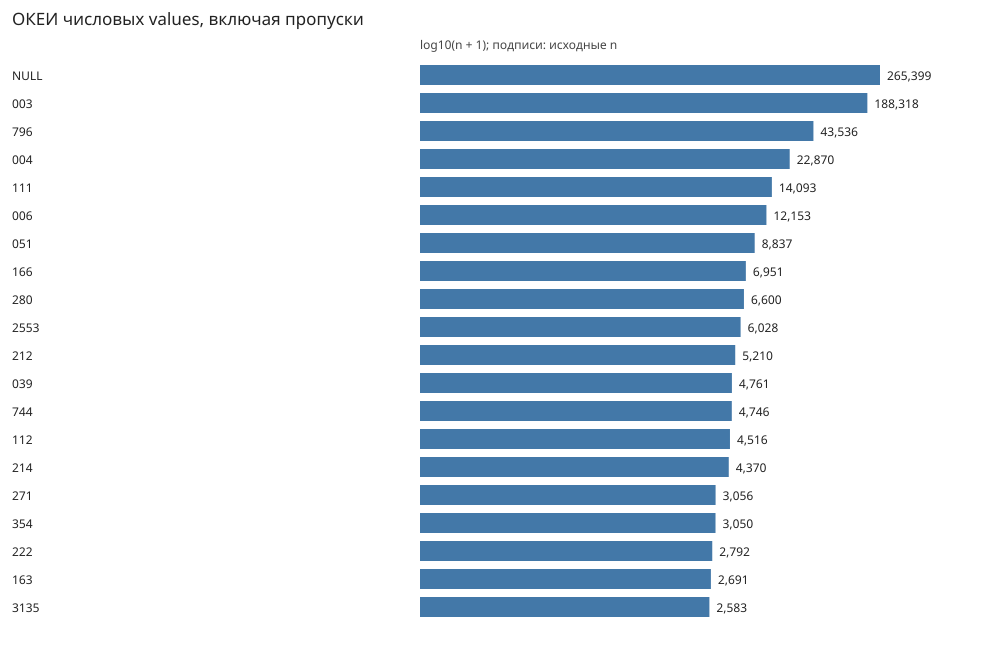

names_with_multiple_units.csv: 185 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/names_with_multiple_units.csv


,name_norm,unit_codes,observed_units,definitions
0,длина,3,"004,003,006",10221
1,толщина,2,"003,004",7021
2,ширина,3,"003,004,006",6154
3,высота,3,"003,004,006",4735
4,диаметр,3,"003,004,039",3937
5,объем,5,"111,642,112,113,796",3239
6,объем реагента,3,"D111,111,112",2591
7,внешний диаметр,2,"003,004",1198
8,диаметр диска,2,"003,004",1192
9,пропускная способность,6,"2547,2545,598,535,534,499",901


okei_label_conflicts.csv: 3 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/okei_label_conflicts.csv


,code,names,labels
0,111,3,"Кубический сантиметр; миллилитр,Миллилитр,Куби..."
1,112,2,"Литр; кубический дециметр,Литр;^кубический дец..."
2,168,2,"Тонна; метрическая тонна (1000 кг),Тонна;^метр..."


In [14]:
unit_coverage = q("""SELECT COALESCE(rub.name,'без рубрикатора') rubric,COUNT(DISTINCT v.id) numeric_values,
COUNT(DISTINCT CASE WHEN v.okei_code IS NULL THEN v.id END) missing_unit
FROM ktru_value v JOIN ktru_characteristic c ON c.id=v.characteristic_id
LEFT JOIN ktru_rubric rub ON rub.record_id=c.record_id WHERE v.representation='numeric'
GROUP BY rubric ORDER BY numeric_values DESC""")
unit_coverage["missing_pct"] = 100*unit_coverage.missing_unit/unit_coverage.numeric_values
evidence("unit_coverage_by_rubric.csv", unit_coverage)
print("Рубрикаторы могут пересекаться: суммы строк не являются общим знаменателем")
display(q("SELECT COUNT(*) numeric_values,SUM(okei_code IS NULL) missing_unit FROM ktru_value WHERE representation='numeric'"))
unit_distribution = q("SELECT COALESCE(okei_code,'NULL') unit_code,COUNT(*) n FROM ktru_value WHERE representation='numeric' GROUP BY okei_code ORDER BY n DESC")
bars(unit_distribution, "unit_code", "n", "ОКЕИ числовых values, включая пропуски", limit=20, log=True)
ambiguous_units = q("""SELECT c.name_norm,COUNT(DISTINCT v.okei_code) unit_codes,
GROUP_CONCAT(DISTINCT v.okei_code) observed_units,COUNT(DISTINCT c.id) definitions
FROM ktru_characteristic c JOIN ktru_value v ON v.characteristic_id=c.id
WHERE c.actual=1 AND v.representation='numeric' GROUP BY c.name_norm HAVING unit_codes>1 ORDER BY definitions DESC""")
evidence("names_with_multiple_units.csv", ambiguous_units)
unit_labels = q("""SELECT code,COUNT(DISTINCT name) names,GROUP_CONCAT(DISTINCT name) labels FROM (
SELECT okei_code code,name FROM ktru_position_unit UNION ALL SELECT okei_code,okei_name FROM ktru_value
) WHERE code IS NOT NULL GROUP BY code HAVING names>1""")
evidence("okei_label_conflicts.csv", unit_labels)

In [15]:
definition_units = q("""SELECT c.id,c.record_id,COUNT(v.id) numeric_options,
SUM(v.okei_code IS NULL) missing_unit_options,COUNT(DISTINCT v.okei_code) distinct_units
FROM ktru_characteristic c JOIN ktru_value v ON v.characteristic_id=c.id
WHERE v.representation='numeric' GROUP BY c.id""")
definition_units["eligible"] = definition_units.record_id.isin(eligible_ids)
coverage_rows = []
for population,group in [("all source",definition_units),("eligible selected",definition_units[definition_units.eligible])]:
    coverage_rows.extend([
        (population,"numeric values",int(group.numeric_options.sum()),int(group.missing_unit_options.sum())),
        (population,"numeric definitions: at least one missing unit",len(group),int((group.missing_unit_options>0).sum())),
        (population,"numeric definitions: all options missing unit",len(group),int((group.missing_unit_options==group.numeric_options).sum())),
        (population,"numeric definitions: multiple explicit units",len(group),int((group.distinct_units>1).sum())),
    ])
coverage = pd.DataFrame(coverage_rows,columns=["population","denominator_kind","denominator","affected"])
coverage["pct"] = 100*coverage.affected/coverage.denominator
display(coverage)

count_units = {record_id:set() for record_id in POS.id}
for record_id,unit in conn.execute("SELECT record_id,okei_code FROM ktru_position_unit"):
    if record_id in count_units and unit is not None:
        count_units[record_id].add(unit)
physical_units = {}
for char_id,record_id,unit in conn.execute("SELECT c.id,c.record_id,v.okei_code FROM ktru_characteristic c JOIN ktru_value v ON v.characteristic_id=c.id WHERE v.representation='numeric'"):
    physical_units.setdefault((record_id,char_id),set()).add(unit)
unit_relationship = []
for (record_id,char_id),units in physical_units.items():
    if record_id not in count_units:
        continue
    position_units = count_units[record_id]
    explicit_units = units-{None}
    relation = "position unit missing" if not position_units else "physical unit missing" if not explicit_units else "some codes overlap" if position_units & explicit_units else "different unit roles"
    unit_relationship.append((record_id,char_id,relation,sorted(position_units),sorted(explicit_units)))
unit_relationship = pd.DataFrame(unit_relationship,columns=["record_id","characteristic_id","relation","position_units","physical_units"])
display(unit_relationship.relation.value_counts().rename_axis("relation").reset_index(name="numeric_definitions"))
print("Selected records без единицы счёта:",sum(not units for units in count_units.values()),"из",len(POS))
evidence("position_vs_physical_units.csv",unit_relationship.groupby("relation",group_keys=False).head(5))
print("Разные роли единиц не являются дефектом: шт. позиции и мм её длины ожидаемо различаются.")

,population,denominator_kind,denominator,affected,pct
0,all source,numeric values,650311,265399,40.811089
1,all source,numeric definitions: at least one missing unit,146229,13261,9.068653
2,all source,numeric definitions: all options missing unit,146229,13261,9.068653
3,all source,numeric definitions: multiple explicit units,146229,2,0.001368
4,eligible selected,numeric values,258303,36521,14.138821
5,eligible selected,numeric definitions: at least one missing unit,89374,6730,7.530154
6,eligible selected,numeric definitions: all options missing unit,89374,6730,7.530154
7,eligible selected,numeric definitions: multiple explicit units,89374,1,0.001119


,relation,numeric_definitions
0,different unit roles,118872
1,physical unit missing,13260
2,some codes overlap,8137
3,position unit missing,5958


Selected records без единицы счёта: 2001 из 81461
position_vs_physical_units.csv: 20 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/position_vs_physical_units.csv


,record_id,characteristic_id,relation,position_units,physical_units
0,1,1,physical unit missing,[796],[]
1,1,2,different unit roles,[796],[055]
2,3,4,different unit roles,[796],[300]
3,3,6,different unit roles,[796],[004]
4,3,7,different unit roles,[796],[003]
5,3,8,different unit roles,[796],[003]
12,11,15,physical unit missing,[796],[]
29,21,61,some codes overlap,[796],[796]
31,22,63,some codes overlap,[796],[796]
33,23,65,some codes overlap,[796],[796]


Разные роли единиц не являются дефектом: шт. позиции и мм её длины ожидаемо различаются.


## 6. Числовые outliers: сначала семантика, потом величина

Обратные/пустые ranges являются структурными исключениями. Большое число само по себе не доказывает ошибку: массу нельзя сравнивать с мощностью, а мм с метрами. Ниже величины рассматриваются в конкретной группе `name + OKPD2 + OKEI + numeric kind`.

IQR-флаг применяется к точкам внутри группы с минимум 8 observations. Это очередь на проверку, не автоочистка. Повторы шаблонов/потомков делают observations зависимыми, поэтому статистические флаги не трактуются как проверка вероятности ошибки. Диапазоны и единицы не объединяются в одну числовую гистограмму.

In [16]:
issues = q("""SELECT d.reason,r.code,r.version,c.name characteristic,v.source_code value_code,
d.detail,f.path,r.ordinal FROM data_issue d JOIN ktru_record r ON r.id=d.record_id
JOIN xml_source_file f ON f.id=r.source_id LEFT JOIN ktru_characteristic c ON c.id=d.characteristic_id
LEFT JOIN ktru_value v ON v.id=d.value_id ORDER BY d.reason,r.code""")
evidence("xml_data_issues.csv", issues)
display(issues.reason.value_counts().rename_axis("reason").reset_index(name="n"))
atoms = q("""SELECT a.id,r.code,r.okpd2_code,c.name,c.name_norm,v.okei_code,a.kind,
a.point,a.lower_bound,a.upper_bound,a.lower_inclusive,a.upper_inclusive FROM ktru_numeric_atom a
JOIN ktru_value v ON v.id=a.value_id JOIN ktru_characteristic c ON c.id=v.characteristic_id
JOIN ktru_selected r ON r.id=c.record_id""")
display(atoms.assign(lower_present=atoms.lower_bound.notna(),upper_present=atoms.upper_bound.notna()).groupby(["kind","lower_present","upper_present"]).size().rename("n").reset_index())
print("Values с несколькими numeric atoms:",conn.execute("SELECT COUNT(*) FROM (SELECT value_id FROM ktru_numeric_atom GROUP BY value_id HAVING COUNT(*)>1)").fetchone()[0])
points = atoms[atoms.kind.eq("point") & atoms.point.notna()].copy()
points["plot_number"] = pd.to_numeric(points.point,errors="coerce")
keys = ["name_norm","okpd2_code","okei_code"]
grouped = points.groupby(keys,dropna=False).plot_number
points["group_n"] = grouped.transform("size")
points["q1"] = grouped.transform(lambda s:s.quantile(.25))
points["q3"] = grouped.transform(lambda s:s.quantile(.75))
spread = points.q3-points.q1
flag = (points.group_n>=8) & (spread>0) & ((points.plot_number<points.q1-1.5*spread)|(points.plot_number>points.q3+1.5*spread))
evidence("numeric_point_iqr_review.csv",points.loc[flag].sort_values(keys))

xml_data_issues.csv: 8 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/xml_data_issues.csv


,reason,code,version,characteristic,value_code,detail,path,ordinal
0,empty_or_reversed_range,25.29.12.000-00000001,3,Температура хранения,02a4156d-c,-100 .. -150,/Users/paul/Projects/hackathon-tenderhack-kaza...,62
1,empty_or_reversed_range,25.29.12.000-00000002,4,Температура хранения,02a4156d-c,-100 .. -150,/Users/paul/Projects/hackathon-tenderhack-kaza...,61
2,empty_or_reversed_range,26.30.50.119-00000007,4,Дальность измерения температуры,f3fd762a-5,5 .. -10,/Users/paul/Projects/hackathon-tenderhack-kaza...,6
3,empty_or_reversed_range,26.30.50.119-00008,4,Дальность измерения температуры,168e3e26-4,5 .. -10,/Users/paul/Projects/hackathon-tenderhack-kaza...,5
4,empty_or_reversed_range,28.99.39.190-00000352,1,Давление кислорода,913a3b65-a,0.7 .. 0.15,/Users/paul/Projects/hackathon-tenderhack-kaza...,931
5,empty_or_reversed_range,28.99.39.190-00000353,1,Давление кислорода,913a3b65-a,0.7 .. 0.15,/Users/paul/Projects/hackathon-tenderhack-kaza...,930
6,empty_or_reversed_range,32.50.13.190-04513,1,Диаметр диска,329d3b08-d,34 .. 34,/Users/paul/Projects/hackathon-tenderhack-kaza...,331
7,empty_or_reversed_range,32.50.22.190-03098,2,Ширина,cca43467-5,160 .. 160,/Users/paul/Projects/hackathon-tenderhack-kaza...,943


,reason,n
0,empty_or_reversed_range,8


,kind,lower_present,upper_present,n
0,point,False,False,306356
1,range,False,True,34560
2,range,True,False,101890
3,range,True,True,207503


Values с несколькими numeric atoms: 0


numeric_point_iqr_review.csv: 2,518 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/numeric_point_iqr_review.csv


,id,code,okpd2_code,name,name_norm,okei_code,kind,point,lower_bound,upper_bound,lower_inclusive,upper_inclusive,plot_number,group_n,q1,q3
515514,515517,23.19.23.110-00000873,23.19.23.110,Вместимость,вместимость,111,point,2000,NaN,NaN,NaN,NaN,2000.00,18,25.0,500.0
515524,515527,23.19.23.110-00000864,23.19.23.110,Вместимость,вместимость,111,point,2000,NaN,NaN,NaN,NaN,2000.00,18,25.0,500.0
418567,418570,22.21.29.120-00000123,22.21.29.120,Внутренний диаметр,внутренний диаметр,003,point,20.05,NaN,NaN,NaN,NaN,20.05,232,4.0,10.0
418611,418614,22.21.29.120-00000104,22.21.29.120,Внутренний диаметр,внутренний диаметр,003,point,20.05,NaN,NaN,NaN,NaN,20.05,232,4.0,10.0
417443,417446,26.60.13.190-00000556,26.60.13.190,Время накопления заряда,время накопления заряда,354,point,15,NaN,NaN,NaN,NaN,15.00,19,7.0,10.0
645408,645411,21.20.24.180-00106,21.20.24.180,Время отверждения,время отверждения,356,point,72,NaN,NaN,NaN,NaN,72.00,50,1.5,24.0
645441,645444,21.20.24.180-00000100,21.20.24.180,Время отверждения,время отверждения,356,point,72,NaN,NaN,NaN,NaN,72.00,50,1.5,24.0
645481,645484,21.20.24.180-00000083,21.20.24.180,Время отверждения,время отверждения,356,point,72,NaN,NaN,NaN,NaN,72.00,50,1.5,24.0
645496,645499,21.20.24.180-00000078,21.20.24.180,Время отверждения,время отверждения,356,point,72,NaN,NaN,NaN,NaN,72.00,50,1.5,24.0
645499,645502,21.20.24.180-00000077,21.20.24.180,Время отверждения,время отверждения,356,point,72,NaN,NaN,NaN,NaN,72.00,50,1.5,24.0


,name_norm,okpd2_code,okei_code
0,"диоптрийный ряд, дптр",32.50.13.120,NaN


count    209180.000000
mean         11.903921
std          18.946715
min         -40.000000
50%          12.250000
90%          38.000000
95%          41.500000
99%          44.250000
max          45.000000
Name: plot_number, dtype: float64

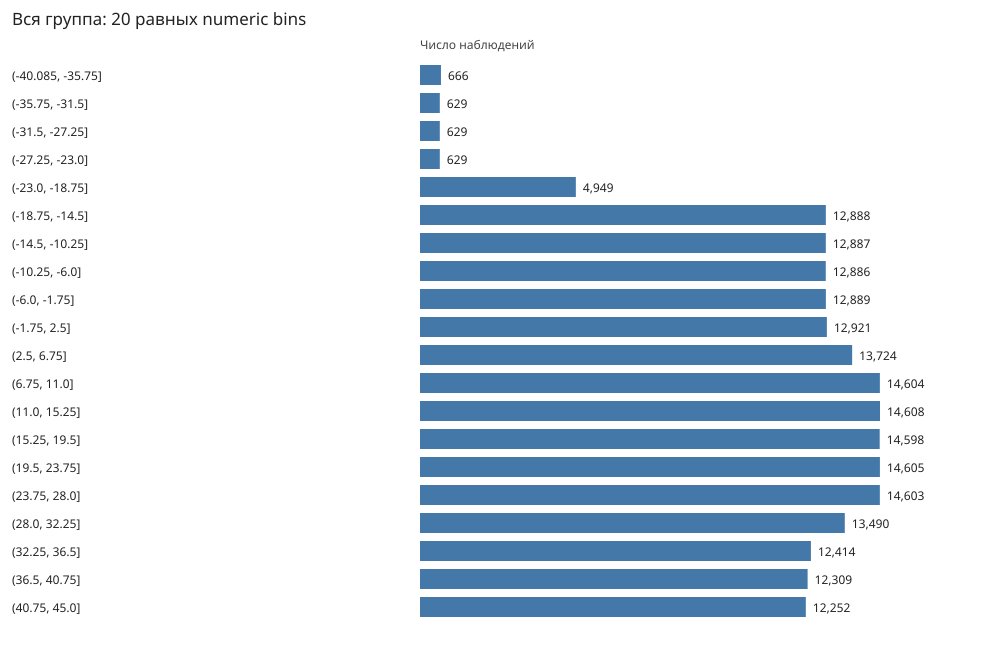

Группа содержит 931 records, 341 разных point strings; template/eligibility ниже


,eligible,is_template,point_options
0,False,0,194932
1,False,1,1182
2,True,0,13066


example_numeric_group.csv: 209,180 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/example_numeric_group.csv


,id,code,okpd2_code,name,name_norm,okei_code,kind,point,lower_bound,upper_bound,lower_inclusive,upper_inclusive,plot_number,group_n,q1,q3
19209,19212,32.50.13.120-00073,32.50.13.120,"Диоптрийный ряд, дптр","диоптрийный ряд, дптр",NaN,point,8,NaN,NaN,NaN,NaN,8.00,209180,-3.75,27.5
19210,19213,32.50.13.120-00073,32.50.13.120,"Диоптрийный ряд, дптр","диоптрийный ряд, дптр",NaN,point,8.25,NaN,NaN,NaN,NaN,8.25,209180,-3.75,27.5
19211,19214,32.50.13.120-00073,32.50.13.120,"Диоптрийный ряд, дптр","диоптрийный ряд, дптр",NaN,point,8.5,NaN,NaN,NaN,NaN,8.50,209180,-3.75,27.5
19212,19215,32.50.13.120-00073,32.50.13.120,"Диоптрийный ряд, дптр","диоптрийный ряд, дптр",NaN,point,8.75,NaN,NaN,NaN,NaN,8.75,209180,-3.75,27.5
19213,19216,32.50.13.120-00073,32.50.13.120,"Диоптрийный ряд, дптр","диоптрийный ряд, дптр",NaN,point,9.25,NaN,NaN,NaN,NaN,9.25,209180,-3.75,27.5
19214,19217,32.50.13.120-00073,32.50.13.120,"Диоптрийный ряд, дптр","диоптрийный ряд, дптр",NaN,point,9.5,NaN,NaN,NaN,NaN,9.50,209180,-3.75,27.5
19215,19218,32.50.13.120-00073,32.50.13.120,"Диоптрийный ряд, дптр","диоптрийный ряд, дптр",NaN,point,9.75,NaN,NaN,NaN,NaN,9.75,209180,-3.75,27.5
19216,19219,32.50.13.120-00073,32.50.13.120,"Диоптрийный ряд, дптр","диоптрийный ряд, дптр",NaN,point,10,NaN,NaN,NaN,NaN,10.00,209180,-3.75,27.5
19217,19220,32.50.13.120-00073,32.50.13.120,"Диоптрийный ряд, дптр","диоптрийный ряд, дптр",NaN,point,10.25,NaN,NaN,NaN,NaN,10.25,209180,-3.75,27.5
19218,19221,32.50.13.120-00073,32.50.13.120,"Диоптрийный ряд, дптр","диоптрийный ряд, дптр",NaN,point,10.5,NaN,NaN,NaN,NaN,10.50,209180,-3.75,27.5


In [17]:
# Иллюстрация группы с наибольшим числом точек, не смешение разных единиц.
if len(points):
    size = points.groupby(keys,dropna=False).size().sort_values(ascending=False)
    selected_key = size.index[0]
    selected = points
    for column,value in zip(keys,selected_key):
        selected = selected[selected[column].isna()] if pd.isna(value) else selected[selected[column].eq(value)]
    histogram = selected.plot_number.value_counts().sort_index().rename_axis("point").reset_index(name="n")
    display(pd.DataFrame([dict(zip(keys,selected_key))]))
    display(selected.plot_number.describe(percentiles=[.5,.9,.95,.99]))
    # Равные интервалы охватывают всю группу, включая оба хвоста.
    binned = pd.cut(selected.plot_number,bins=20,duplicates="drop").value_counts(sort=False).rename_axis("interval").reset_index(name="n")
    bars(binned,"interval","n","Вся группа: 20 равных numeric bins",limit=20)
    print("Группа содержит",selected.code.nunique(),"records,",selected.point.nunique(),"разных point strings; template/eligibility ниже")
    display(selected.merge(POS[["code","eligible","is_template"]],on="code").groupby(["eligible","is_template"]).size().rename("point_options").reset_index())
    evidence("example_numeric_group.csv",selected)

point_options  records
eligible screen_status                               
False    IQR_review_flag                 991      471
         excluded_small_group           1584      606
         excluded_zero_IQR              1303     1113
         screened_not_flagged         243138     6031
True     IQR_review_flag                1527      951
         excluded_small_group           1356      711
         excluded_zero_IQR               644      595
         screened_not_flagged          55813    10019

eligible_numeric_point_iqr_review.csv: 1,527 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/eligible_numeric_point_iqr_review.csv


,id,code,okpd2_code,name,name_norm,okei_code,kind,point,lower_bound,upper_bound,lower_inclusive,upper_inclusive,plot_number,group_n,q1,q3,screen_status,eligible
6407,6408,32.50.50.000-00082,32.50.50.000,Длина стента до установки,длина стента до установки,003,point,240,NaN,NaN,NaN,NaN,240.0,30,28.50,81.75,IQR_review_flag,True
6443,6444,32.50.50.000-00079,32.50.50.000,Длина стента до установки,длина стента до установки,003,point,190,NaN,NaN,NaN,NaN,190.0,30,28.50,81.75,IQR_review_flag,True
17639,17640,32.50.13.190-01444,32.50.13.190,Диаметр стента,диаметр стента,003,point,7,NaN,NaN,NaN,NaN,7.0,18,2.75,4.00,IQR_review_flag,True
45256,45259,32.50.22.190-02794,32.50.22.190,Длина,длина,003,point,100,NaN,NaN,NaN,NaN,100.0,468,3.75,8.00,IQR_review_flag,True
256376,256379,32.50.13.190-02615,32.50.13.190,Диаметр стента,диаметр стента,003,point,6,NaN,NaN,NaN,NaN,6.0,18,2.75,4.00,IQR_review_flag,True
289512,289515,32.50.22.190-00004845,32.50.22.190,Длина,длина,003,point,19,NaN,NaN,NaN,NaN,19.0,468,3.75,8.00,IQR_review_flag,True
289515,289518,32.50.22.190-00004844,32.50.22.190,Длина,длина,003,point,19,NaN,NaN,NaN,NaN,19.0,468,3.75,8.00,IQR_review_flag,True
289518,289521,32.50.22.190-00004843,32.50.22.190,Длина,длина,003,point,19,NaN,NaN,NaN,NaN,19.0,468,3.75,8.00,IQR_review_flag,True
294165,294168,32.50.22.129-00000002,32.50.22.129,Высота,высота,003,point,39,NaN,NaN,NaN,NaN,39.0,26,550.00,870.00,IQR_review_flag,True
294166,294169,32.50.22.129-00000002,32.50.22.129,Высота,высота,003,point,44,NaN,NaN,NaN,NaN,44.0,26,550.00,870.00,IQR_review_flag,True


,eligible,lower_open,upper_open,range_options
0,False,False,False,84644
1,False,False,True,44071
2,False,True,False,16275
3,True,False,False,122859
4,True,False,True,57819
5,True,True,False,18285


Range group: {'name_norm': 'эффективная площадь сечения', 'okpd2_code': '32.50.22.190', 'okei_code': '051'} ; options: 8453 records: 53


count    8453.000000
mean        4.813796
std         1.463644
min         2.280000
50%         4.790000
90%         6.860000
95%         7.100000
99%         7.310000
max         7.340000
Name: lower_bound, dtype: float64

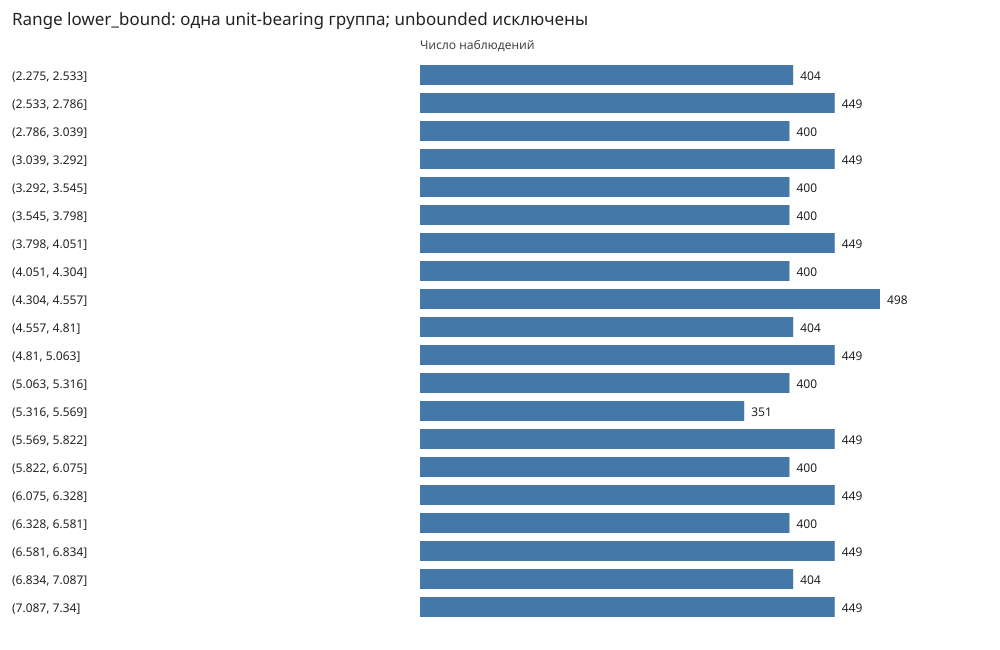

count    8453.000000
mean        4.851424
std         1.464203
min         2.330000
50%         4.850000
90%         6.890000
95%         7.130000
99%         7.340000
max         7.440000
Name: upper_bound, dtype: float64

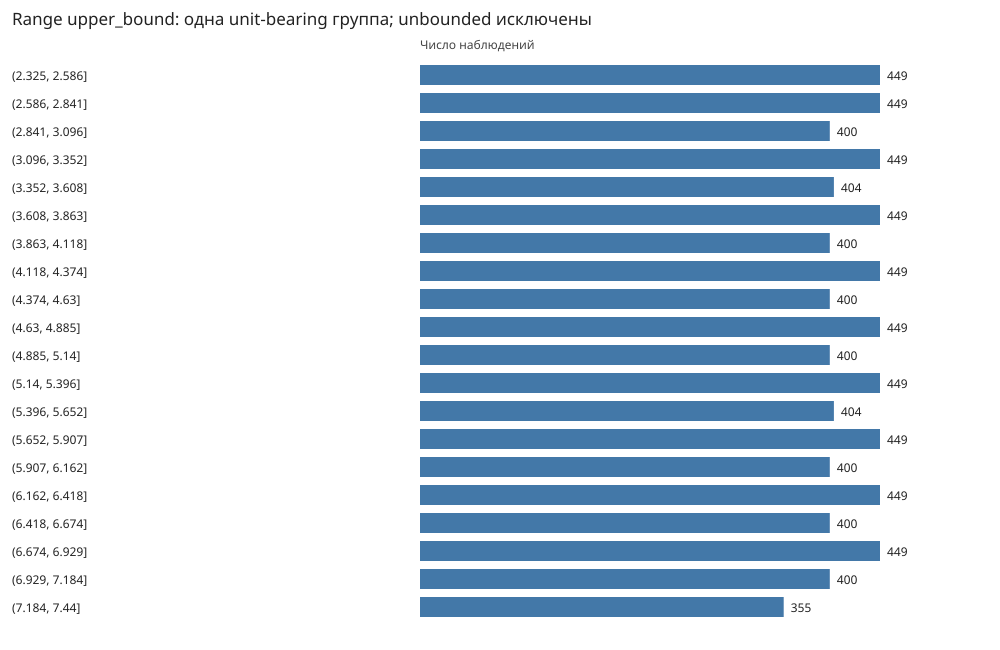

example_numeric_range_group.csv: 8,453 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/example_numeric_range_group.csv


,id,code,okpd2_code,name,name_norm,okei_code,kind,point,lower_bound,upper_bound,lower_inclusive,upper_inclusive,eligible
45063,45066,32.50.22.190-02788,32.50.22.190,Эффективная площадь сечения,эффективная площадь сечения,051,range,NaN,3.44,3.47,1.0,1.0,False
45064,45067,32.50.22.190-02788,32.50.22.190,Эффективная площадь сечения,эффективная площадь сечения,051,range,NaN,3.47,3.5,1.0,1.0,False
45065,45068,32.50.22.190-02788,32.50.22.190,Эффективная площадь сечения,эффективная площадь сечения,051,range,NaN,3.5,3.53,1.0,1.0,False
45066,45069,32.50.22.190-02788,32.50.22.190,Эффективная площадь сечения,эффективная площадь сечения,051,range,NaN,3.53,3.56,1.0,1.0,False
45067,45070,32.50.22.190-02788,32.50.22.190,Эффективная площадь сечения,эффективная площадь сечения,051,range,NaN,3.56,3.59,1.0,1.0,False
45068,45071,32.50.22.190-02788,32.50.22.190,Эффективная площадь сечения,эффективная площадь сечения,051,range,NaN,3.59,3.62,1.0,1.0,False
45069,45072,32.50.22.190-02788,32.50.22.190,Эффективная площадь сечения,эффективная площадь сечения,051,range,NaN,3.62,3.65,1.0,1.0,False
45070,45073,32.50.22.190-02788,32.50.22.190,Эффективная площадь сечения,эффективная площадь сечения,051,range,NaN,3.65,3.68,1.0,1.0,False
45071,45074,32.50.22.190-02788,32.50.22.190,Эффективная площадь сечения,эффективная площадь сечения,051,range,NaN,3.68,3.71,1.0,1.0,False
45072,45075,32.50.22.190-02788,32.50.22.190,Эффективная площадь сечения,эффективная площадь сечения,051,range,NaN,3.71,3.74,1.0,1.0,False


Range bounds показаны для одной группы; остальные группы не прошли IQR point screening.


In [18]:
# Coverage screening, not a claim that all numeric options are independent samples.
screen_status = pd.Series("screened_not_flagged",index=points.index)
screen_status[points.group_n<8] = "excluded_small_group"
screen_status[(points.group_n>=8)&(spread==0)] = "excluded_zero_IQR"
screen_status[flag] = "IQR_review_flag"
points["screen_status"] = screen_status
points["eligible"] = points.code.isin(POS.loc[POS.eligible,"code"])
display(points.groupby(["eligible","screen_status"]).agg(point_options=("id","size"),records=("code","nunique")))
evidence("eligible_numeric_point_iqr_review.csv",points[points.eligible & flag])
ranges = atoms[atoms.kind.eq("range")].copy()
ranges["eligible"] = ranges.code.isin(POS.loc[POS.eligible,"code"])
display(ranges.assign(lower_open=ranges.lower_bound.isna(),upper_open=ranges.upper_bound.isna()).groupby(["eligible","lower_open","upper_open"]).size().rename("range_options").reset_index())
# Range bounds: choose one explicitly unit-bearing group; no cross-unit mixing.
range_groups = ranges[ranges.okei_code.notna()].groupby(keys,dropna=False).size().sort_values(ascending=False)
if len(range_groups):
    key = range_groups.index[0]
    group = ranges
    for column,value in zip(keys,key):
        group = group[group[column].isna()] if pd.isna(value) else group[group[column].eq(value)]
    print("Range group:",dict(zip(keys,key)),"; options:",len(group),"records:",group.code.nunique())
    for column in ("lower_bound","upper_bound"):
        numbers = pd.to_numeric(group[column],errors="coerce").dropna()
        if len(numbers):
            display(numbers.describe(percentiles=[.5,.9,.95,.99]))
            histogram = pd.cut(numbers,bins=20,duplicates="drop").value_counts(sort=False).rename_axis("interval").reset_index(name="n")
            bars(histogram,"interval","n",f"Range {column}: одна unit-bearing группа; unbounded исключены",limit=20)
    evidence("example_numeric_range_group.csv",group)
print("Range bounds показаны для одной группы; остальные группы не прошли IQR point screening.")

## 7. XLSX: реальная полнота и карантин

`Лист1` содержит СТЕ; `Лист2` содержит category/КПГЗ определения и ссылки на эталонные характеристики СПГЗ. Reference ID СПГЗ не является ID СПГЗ-позиции. Поставленная таблица не даёт общего соответствия СТЕ–КПГЗ или КПГЗ–КТРУ.

Повреждения: continuation rows из-за длинных ячеек, overflow-колонки, embedded tabs/records, Excel auto-conversion в даты/проценты, unresolved ID markers. Исходные ячейки, их тип и number format сохраняются. Контроль структуры не доказывает семантическую чистоту; даты и числовые G не восстанавливаются угадыванием.

Карантин не удаляет строку из source. Пропавшие значения и shifted СПГЗ IDs остаются в raw, но в нормализованные определения не попадают. Поэтому downstream coverage ниже числа всех исходных строк. СПГЗ values пока TEXT: разбор интервалов/enum должен быть отдельным проверенным адаптером; произвольный split по `;` не решает проблему.

,path,sheet,raw_rows_including_header,flagged_rows,nonnormalized_rows
0,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист1,99999,2,2
1,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист2,41353,4155,350
2,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист1,99996,4,4
3,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист2,42396,916,77
4,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист1,99994,5,5
5,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист2,22906,1424,125


,table,n
0,ste_record,299975
1,kpgz_entry,617
2,category_characteristic,106100
3,spgz_reference_occurrence,32481
4,sparse_ktru_assertion,6


xlsx_issue_counts.csv: 29 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/xlsx_issue_counts.csv


,issue,n
0,non_string_cell:I,3031
1,unresolved_value_ids:G,1644
2,excel_date_or_time:G,671
3,unresolved_value_ids:G; non_string_cell:I,220
4,possible_cell_continuation:G; unresolved_value...,197
5,missing_or_invalid_kpgz_code; invalid_characte...,190
6,possible_cell_continuation:A; missing_or_inval...,94
7,possible_cell_continuation:G,92
8,possible_cell_continuation:A; unresolved_value...,78
9,formula_or_error:G,73


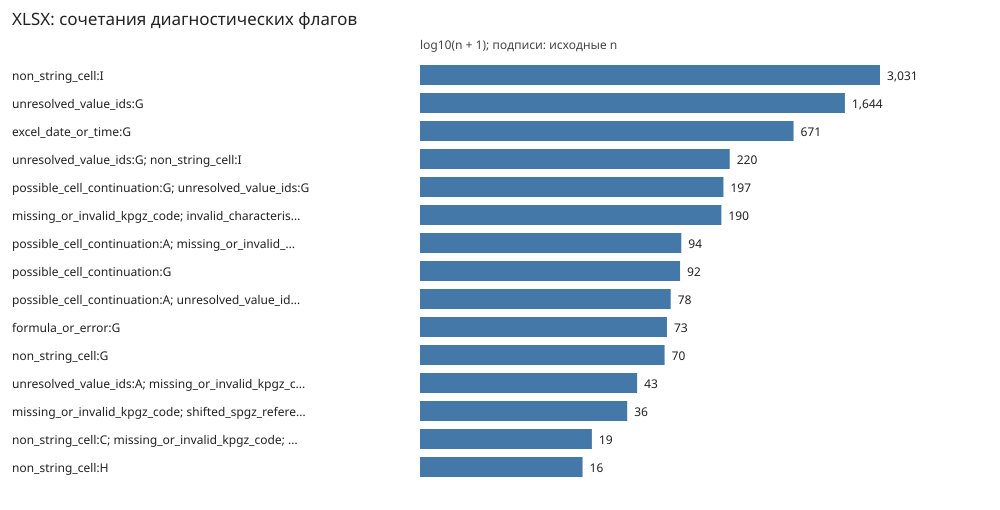

xlsx_quarantine.csv: 563 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/xlsx_quarantine.csv


,path,sheet,row_number,issue,raw_preview
0,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист1,42517,embedded_records_or_tabs:B,"[""34844663"", ""Струбцина F-образная HF-30/8 ти..."
1,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист1,72317,embedded_records_or_tabs:B,"[""35055298"", ""BREXIT Клупп резьбонарезной элек..."
2,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист2,38,formula_or_error:G,"[""Тестеры сетевые"", ""01.11.02.03.26"", ""ТЕСТЕРЫ..."
3,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист2,176,formula_or_error:G,"[""Тестеры сетевые"", ""01.11.02.03.26"", ""ТЕСТЕРЫ..."
4,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист2,338,unresolved_value_ids:A; missing_or_invalid_kpg...,"[""ачение ID: 320294605]; [не найдено значение ..."
5,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист2,628,missing_or_invalid_kpgz_code; invalid_characte...,"[""стений; Стеллаж кассетный для хранения предм..."
6,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист2,1470,excel_date_or_time:G; unresolved_value_ids:H; ...,"[""Заклепочники"", ""01.11.02.01.17"", ""ЗАКЛЕПОЧНИ..."
7,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист2,1543,unresolved_value_ids:H; embedded_records_or_ta...,"[""Краскораспылители"", ""01.11.02.01.72"", ""КРАСК..."
8,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист2,2324,possible_cell_continuation:A; missing_or_inval...,"[""йс; дополнительная рукоятка, ограничитель гл..."
9,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист2,2325,missing_or_invalid_kpgz_code; invalid_characte...,"[""дное устройство, "", null, null, null, null, ..."


raw_preview обрезан для CSV; полный raw_cells_json остаётся в DB


In [19]:
xlsx_counts = q("""SELECT f.path,s.sheet,COUNT(*) raw_rows_including_header,
SUM(s.issue IS NOT NULL) flagged_rows,
SUM(s.row_number>1 AND NOT EXISTS(SELECT 1 FROM ste_record t WHERE t.source_row_id=s.id)
 AND NOT EXISTS(SELECT 1 FROM category_characteristic c WHERE c.source_row_id=s.id)) nonnormalized_rows
FROM xlsx_source_row s JOIN xlsx_source_file f ON f.id=s.source_id GROUP BY f.id,s.sheet""")
display(xlsx_counts)
xlsx_table_counts = pd.DataFrame([(t,conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]) for t in ["ste_record","kpgz_entry","category_characteristic","spgz_reference_occurrence","sparse_ktru_assertion"]],columns=["table","n"])
display(xlsx_table_counts)
xlsx_issues = q("SELECT issue,COUNT(*) n FROM xlsx_source_row WHERE issue IS NOT NULL GROUP BY issue ORDER BY n DESC")
evidence("xlsx_issue_counts.csv",xlsx_issues)
bars(xlsx_issues,"issue","n","XLSX: сочетания диагностических флагов",limit=15,log=True)
quarantine = q("""SELECT f.path,s.sheet,s.row_number,s.issue,SUBSTR(s.raw_cells_json,1,1000) raw_preview
FROM xlsx_source_row s JOIN xlsx_source_file f ON f.id=s.source_id
WHERE s.row_number>1 AND NOT EXISTS(SELECT 1 FROM ste_record t WHERE t.source_row_id=s.id)
AND NOT EXISTS(SELECT 1 FROM category_characteristic c WHERE c.source_row_id=s.id) ORDER BY f.path,s.sheet,s.row_number""")
evidence("xlsx_quarantine.csv",quarantine)
print("raw_preview обрезан для CSV; полный raw_cells_json остаётся в DB")

,occurrences,reference_ids,flagged_occurrences,absent_value_blocks
0,32481,32456,224,984


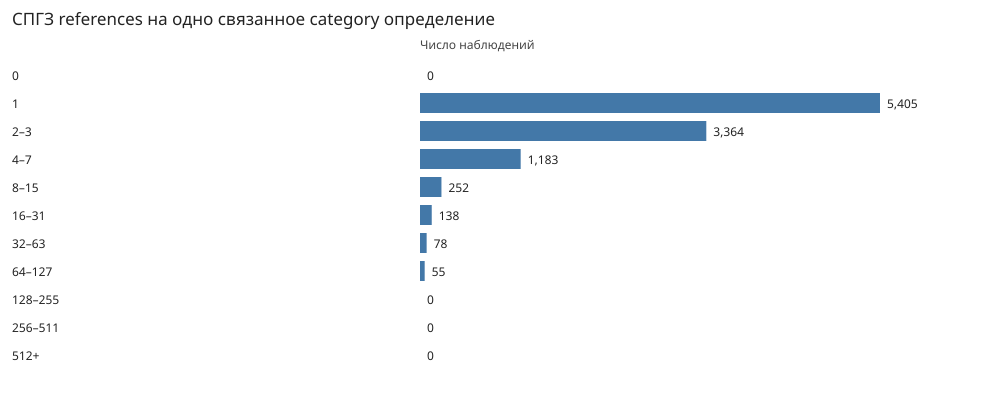

spgz_incomplete_occurrences.csv: 1,159 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/spgz_incomplete_occurrences.csv


,id,category_characteristic_id,ordinal,reference_code,name,values_raw,parse_issue
0,3773,32922,1,11549779,Каталожный номер (Артикул),,NaN
1,4716,39666,1,11549732,Каталожный номер (Артикул),,NaN
2,5112,41352,1,5517154,Требования к цветовому решению,,NaN
3,5113,41352,2,5517260,Требования к цветовому решению,,NaN
4,5114,41353,1,5517200,Требования к фактуре материала,,NaN
5,5115,41353,2,5517229,Требования к фактуре материала,,NaN
6,5116,41354,1,5517184,Требования к фурнитуре,,NaN
7,5117,41354,2,5517215,Требования к фурнитуре,,NaN
8,5185,41870,1,10941088,Требования к фурнитуре,,NaN
9,5186,41870,2,10941124,Требования к фурнитуре,,NaN


spgz_reference_identity_conflicts.csv: 0 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/spgz_reference_identity_conflicts.csv


,reference_code,names,value_sets


sparse_ktru_assertions.csv: 6 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/sparse_ktru_assertions.csv


,code,field,path,sheet,row_number,code_observed,code_selected,evidence_preview
0,31.01.12.160-00000005,Характеристики,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист1,21994,1,1,Артикул производителя 137257 | В разобранном в...
1,31.01.12.160-00000005,Наименование СТЕ,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист1,31136,1,1,"Кресло офисное , 31.01.12.160-00000005"
2,31.01.12.160-00000005,Наименование СТЕ,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист1,31199,1,1,"Кресло офисное, 31.01.12.160-00000005"
3,31.09.10.000-00000018,Наименование СТЕ,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист1,69840,1,1,"Табурет ""РМ"" КТРУ 31.09.10.000-00000018, РМ4-Т..."
4,31.01.12.160-00000005,Значения характеристики,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист2,18580,1,1,31.01.12.160-00000005
5,14.12.30.190-00000007,Наименование СТЕ,/Users/paul/Projects/hackathon-tenderhack-kaza...,Лист1,73719,1,1,"Костюм изолирующий, ""Д-Медфарм"" 14.12.30.190-0..."


,id,kpgz_code,ktru_code,state,method,evidence,source_row_id
0,1,01.16.04.02,31.01.12.160-00000005,proposed,explicit_source_assertion,31.01.12.160-00000005,259928


In [20]:
spgz_status = q("""SELECT COUNT(*) occurrences,COUNT(DISTINCT reference_code) reference_ids,
SUM(parse_issue IS NOT NULL) flagged_occurrences,SUM(values_raw IS NULL OR TRIM(values_raw)='') absent_value_blocks
FROM spgz_reference_occurrence""")
display(spgz_status)
spgz_multiplicity = q("SELECT category_characteristic_id,COUNT(*) n FROM spgz_reference_occurrence GROUP BY category_characteristic_id")
bars(count_distribution(spgz_multiplicity.n),"bucket","n","СПГЗ references на одно связанное category определение",limit=20)
evidence("spgz_incomplete_occurrences.csv",q("SELECT * FROM spgz_reference_occurrence WHERE parse_issue IS NOT NULL OR values_raw IS NULL OR TRIM(values_raw)=''"))
ref_identity_conflicts = q("""SELECT reference_code,COUNT(DISTINCT name) names,COUNT(DISTINCT values_raw) value_sets
FROM spgz_reference_occurrence GROUP BY reference_code HAVING names>1 OR value_sets>1""")
evidence("spgz_reference_identity_conflicts.csv",ref_identity_conflicts)
sparse = q("""SELECT a.code,a.field,f.path,s.sheet,s.row_number,
EXISTS(SELECT 1 FROM ktru_code k WHERE k.code=a.code) code_observed,
EXISTS(SELECT 1 FROM ktru_selected k WHERE k.code=a.code) code_selected,
SUBSTR(a.evidence,1,500) evidence_preview FROM sparse_ktru_assertion a
JOIN xlsx_source_row s ON s.id=a.source_row_id JOIN xlsx_source_file f ON f.id=s.source_id""")
evidence("sparse_ktru_assertions.csv",sparse)
display(q("SELECT * FROM kpgz_ktru_link"))

### Семантическая грязь: данные против собственной категории

Проверка структуры, KPGZ prefix и foreign keys не обнаруживает значения от другого товара внутри корректной строки. Поиск по полным нормализованным `category_characteristic.values_raw` находит повторённые чужие описания. Правила в `catalogue_domain_audit.py` ограничены контекстом категории/характеристики; это documented review queue, не универсальный classifier и не автоматическая очистка.

Различаем источники:

- **Лист2, G**: допустимые значения category/КПГЗ характеристики.
- **Лист2, I–K**: ID/name/values связанной эталонной **характеристики** СПГЗ. Наличие I не делает G значениями СПГЗ.
- **Лист1, B/F**: название и наблюдаемые свойства СТЕ. У СТЕ здесь нет leaf-category FK: противоречие относится к domain workbook, не выдуманной категории.

Подтверждённые примеры, включая прямое чтение XLSX source cells:

| Файл / лист / ячейка | Собственная категория / характеристика | Чужое содержимое |
|---|---|---|
| Инструменты / Лист2 / G31448 | Флюсы / Вид упаковки | Стерильная ампула с двумя титановыми фиксаторами **имплантата** |
| Инструменты / Лист2 / G31452 | Флюсы / Назначение | Снятие оттисков с имплантатов, установка имплантов, мостовидный протез |
| Инструменты / Лист2 / G7391 | Ключи для винтов с внутренним шестигранником / Материал ключа | Реалистичные венозные трубки для тренажёра постановки центрального венозного катетера |
| Мебель / Лист2 / G41914 | Подиумы выставочные / Материал корпуса | То же описание венозных трубок |
| Одежда / Лист2 / G16869, G21411 | Сумки / Обложки для документов / Материал | То же описание венозных трубок |
| Мебель / Лист2 / G27215 | Стеллажи складские металлические / Вид стеллажа | Картофелемялка, ложки, пресс для чеснока и другая кухонная утварь |
| Инструменты / Лист2 / G15958 | Дальномеры лазерные / Вид изделия | Кастрюля, картофелемялка, кондитерские принадлежности |
| Одежда / Лист2 / G4166, G6644 | Защитная промышленная одежда / Комплектация | Катетеры, оборудование инфузии, интубации и другие medical-kit options |
| Мебель / Лист2 / G6425 | Стеллажи детские / Состав набора | Фигурки богов, карты улик и тайных ролей из настольных игр |

Описание тренажёра повторяется в **23 определениях / 22 категориях**: 9 tools, 9 furniture, 5 clothing. Implant passages встречаются в 8 tool definitions: два flux rows и шесть списков назначения, описывающих дезинфекцию вместо строительного инструмента.

Для этих passage rules совпадений в linked SPGZ K и imported STE B/F **нет**. Например, row 27215 содержит грязный G, но K5974862 перечисляет реальные виды стеллажей; в row 21411 K3776077/3776078 содержит кожу и пластик, а не катетеры. Это положительное различие качества источников, не доказательство чистоты всей СПГЗ.

Слова «медицинский», «шприц», «автомобиль», «шоколад» сами по себе не используются как anomaly: surgical clothing, furniture for medicine storage, sealant syringe, automotive tools и цвет «шоколад» имеют допустимый контекст. Implant marker в данном audit запускает mismatch лишь в упаковке/назначении строительных tool categories.


Clear rule flags: 47 ; distinct source definition rows: 46
STE placement candidates: 3
Coverage: normalized rows only; quarantined source rows are not semantically classified.


,rule,domain,flags,categories
0,automotive_oil_type,Инструменты,8,8
1,automotive_oil_type,Мебель,1,1
2,boardgame_in_furniture,Мебель,1,1
3,catheter_training_material,Инструменты,9,8
4,catheter_training_material,Мебель,9,9
5,catheter_training_material,Одежда,5,5
6,implant_descriptions,Инструменты,8,7
7,kitchenware_type,Инструменты,2,2
8,kitchenware_type,Мебель,2,2
9,medical_kit_in_clothing,Одежда,2,2


,rule,category_G_hits,spgz_K_hits,ste_B_hits,ste_F_hits
0,catheter_training_material,23,0,0,0
1,implant_descriptions,8,0,0,0
2,medical_kit_in_clothing,2,0,0,0
3,boardgame_in_furniture,1,0,0,0
4,kitchenware_type,4,0,0,0
5,automotive_oil_type,9,0,0,0


domain_contamination_findings.csv: 50 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/domain_contamination_findings.csv


,source_row_id,workbook,domain,sheet,row_number,cell,entity_kind,entity_id,kpgz_code,category,characteristic,role,rule,assessment,reason,matched_markers,evidence,linked_reference_ids,linked_reference_same_marker_hits,source_issue
0,104832,Инструменты.xlsx,Инструменты,Лист2,4833,G4833,category_allowed_values,4817,01.11.02.01.08.03,Шлифмашины,Вид,Эталонная,automotive_oil_type,clear_category_value_mismatch,Автомобильное масло предлагается как тип инстр...,автомобильное масло,[не найдено значение ID: 323681055]; Автомобил...,11225297 | 11225377 | 11225391 | 11225398 | 11...,0.0,unresolved_value_ids:G
1,106117,Инструменты.xlsx,Инструменты,Лист2,6118,G6118,category_allowed_values,6099,01.11.02.02.07.02,Отвертки,Вид товаров,Базовая,automotive_oil_type,clear_category_value_mismatch,Автомобильное масло предлагается как тип инстр...,автомобильное масло,АВТОМОБИЛЬНОЕ МАСЛО; Аккумулятор; Вентиль (кор...,,0.0,NaN
2,107074,Инструменты.xlsx,Инструменты,Лист2,7075,G7075,category_allowed_values,7048,01.11.02.02.07.01.03,Ключи гаечные торцовые,Вид товаров,Базовая,automotive_oil_type,clear_category_value_mismatch,Автомобильное масло предлагается как тип инстр...,автомобильное масло,АВТОМОБИЛЬНОЕ МАСЛО; Аккумулятор; Вентиль (кор...,,0.0,NaN
3,107390,Инструменты.xlsx,Инструменты,Лист2,7391,G7391,category_allowed_values,7362,01.11.02.02.07.01.07,Ключи для винтов с внутренним шестигранником,Материал ключа,Эталонная,catheter_training_material,clear_category_value_mismatch,"Описание тренажёра постановки ЦВК, не материал...",венозные трубки изготовлены,"тон (fpm); Ватман; Вгп черная, сталь; Вельвет;...",,0.0,possible_cell_continuation:G; unresolved_value...
4,110927,Инструменты.xlsx,Инструменты,Лист2,10928,G10928,category_allowed_values,10883,01.11.02.06.03.02,Траверсы,Материал,Базовая,catheter_training_material,clear_category_value_mismatch,"Описание тренажёра постановки ЦВК, не материал...",венозные трубки изготовлены,"тон (fpm); Ватман; ВГП черная, сталь; Вельвет;...",,0.0,possible_cell_continuation:G
5,111182,Инструменты.xlsx,Инструменты,Лист2,11183,G11183,category_allowed_values,11136,01.11.02.09.03,Биты для шуруповертов,Материал,Базовая,catheter_training_material,clear_category_value_mismatch,"Описание тренажёра постановки ЦВК, не материал...",венозные трубки изготовлены,"тон (fpm); Ватман; ВГП черная, сталь; Вельвет;...",,0.0,possible_cell_continuation:G
6,115118,Инструменты.xlsx,Инструменты,Лист2,15119,G15119,category_allowed_values,15034,01.11.02.10.01,Скобы для степлера строительного,Материал,Эталонная,catheter_training_material,clear_category_value_mismatch,"Описание тренажёра постановки ЦВК, не материал...",венозные трубки изготовлены,"тон (fpm); Ватман; ВГП черная, сталь; Вельвет;...",,0.0,possible_cell_continuation:G
7,115957,Инструменты.xlsx,Инструменты,Лист2,15958,G15958,category_allowed_values,15866,01.11.02.03.08,Дальномеры лазерные,Вид изделия,Базовая,kitchenware_type,clear_category_value_mismatch,Кухонная утварь предлагается как тип измерител...,картофелемялка,вать точность прибора и получать всегда точные...,,0.0,NaN
8,117232,Инструменты.xlsx,Инструменты,Лист2,17233,G17233,category_allowed_values,17123,01.11.02.03.02,Инструмент мерительный ручной,Вид,Эталонная,kitchenware_type,clear_category_value_mismatch,Кухонная утварь предлагается как тип измерител...,картофелемялка,ационный; Канистра 5 литров пэт; Канцелярский;...,5876237 | 5876242 | 5876251 | 5876257 | 587627...,0.0,unresolved_value_ids:G
9,117232,Инструменты.xlsx,Инструменты,Лист2,17233,G17233,category_allowed_values,17123,01.11.02.03.02,Инструмент мерительный ручной,Вид,Эталонная,automotive_oil_type,clear_category_value_mismatch,Автомобильное масло предлагается как тип инстр...,автомобильное масло,ранспортных средств; Автоматические; Автоматич...,5876237 | 5876242 | 5876251 | 5876257 | 587627...,0.0,unresolved_value_ids:G


domain_contamination_screening.csv: 6 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/domain_contamination_screening.csv


,rule,category_G_hits,spgz_K_hits,ste_B_hits,ste_F_hits
0,catheter_training_material,23,0,0,0
1,implant_descriptions,8,0,0,0
2,medical_kit_in_clothing,2,0,0,0
3,boardgame_in_furniture,1,0,0,0
4,kitchenware_type,4,0,0,0
5,automotive_oil_type,9,0,0,0


category_kpgz_label_disagreement.csv: 63 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/category_kpgz_label_disagreement.csv


,workbook,sheet,row_number,kpgz_code,category_name,kpgz_label,characteristic
0,Инструменты.xlsx,Лист2,40736,01.11.02.03.47,Динамометры электронные,ПРИБОРЫ ДЛЯ КОНТРОЛЯ КАЧЕСТВА ОГНЕЗАЩИТНОЙ ОБР...,Вид продукции
1,Инструменты.xlsx,Лист2,40737,01.11.02.03.47,Динамометры электронные,ПРИБОРЫ ДЛЯ КОНТРОЛЯ КАЧЕСТВА ОГНЕЗАЩИТНОЙ ОБР...,Виды товаров строительных
2,Инструменты.xlsx,Лист2,40738,01.11.02.03.47,Динамометры электронные,ПРИБОРЫ ДЛЯ КОНТРОЛЯ КАЧЕСТВА ОГНЕЗАЩИТНОЙ ОБР...,Виды инструмента и оборудования инструментального
3,Инструменты.xlsx,Лист2,40739,01.11.02.03.47,Динамометры электронные,ПРИБОРЫ ДЛЯ КОНТРОЛЯ КАЧЕСТВА ОГНЕЗАЩИТНОЙ ОБР...,Виды инструмента мерительного
4,Инструменты.xlsx,Лист2,40740,01.11.02.03.47,Динамометры электронные,ПРИБОРЫ ДЛЯ КОНТРОЛЯ КАЧЕСТВА ОГНЕЗАЩИТНОЙ ОБР...,"Выды Инструмент мерительный электронный, оптич..."
5,Инструменты.xlsx,Лист2,40741,01.11.02.03.47,Динамометры электронные,ПРИБОРЫ ДЛЯ КОНТРОЛЯ КАЧЕСТВА ОГНЕЗАЩИТНОЙ ОБР...,Класс точности
6,Инструменты.xlsx,Лист2,40742,01.11.02.03.47,Динамометры электронные,ПРИБОРЫ ДЛЯ КОНТРОЛЯ КАЧЕСТВА ОГНЕЗАЩИТНОЙ ОБР...,Наибольший предел измерения
7,Инструменты.xlsx,Лист2,40743,01.11.02.03.47,Динамометры электронные,ПРИБОРЫ ДЛЯ КОНТРОЛЯ КАЧЕСТВА ОГНЕЗАЩИТНОЙ ОБР...,Вид измеряемой силы
8,Инструменты.xlsx,Лист2,40744,01.11.02.03.47,Динамометры электронные,ПРИБОРЫ ДЛЯ КОНТРОЛЯ КАЧЕСТВА ОГНЕЗАЩИТНОЙ ОБР...,Габаритные размеры
9,Инструменты.xlsx,Лист2,40745,01.11.02.03.47,Динамометры электронные,ПРИБОРЫ ДЛЯ КОНТРОЛЯ КАЧЕСТВА ОГНЕЗАЩИТНОЙ ОБР...,Цена деления шкалы


,workbook,sheet,row_number,entity_id,assessment,evidence
47,Инструменты.xlsx,Лист1,11474,34245155,domain_placement_review,Вешало для сценических костюмов 1500Д*Ш890*200...
48,Инструменты.xlsx,Лист1,11712,34303743,domain_placement_review,"Вешало для сценических костюмов ,мобильное Д1..."
49,Инструменты.xlsx,Лист1,90149,35582253,domain_placement_review,АВТОМАТ ЗАРЯДКИ МОБИЛЬНЫХ ТЕЛЕФОНОВ MOBI AIR Н...


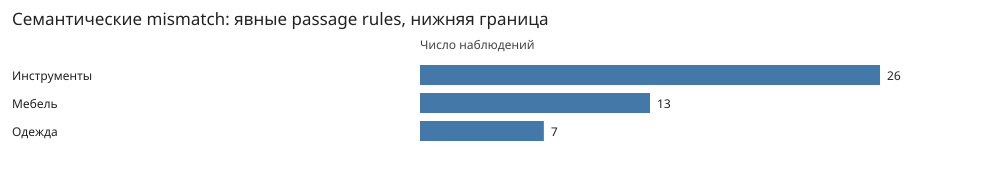

Числа не являются полной contamination rate: absence of these markers does not establish cleanliness.


In [21]:
from catalogue_domain_audit import domain_contamination

domain_findings, domain_screening, category_label_disagreement = domain_contamination(conn)
clear = domain_findings[domain_findings.assessment.eq("clear_category_value_mismatch")]
placement_review = domain_findings[domain_findings.assessment.eq("domain_placement_review")]
print("Clear rule flags:",len(clear),"; distinct source definition rows:",clear.source_row_id.nunique())
print("STE placement candidates:",len(placement_review))
print("Coverage: normalized rows only; quarantined source rows are not semantically classified.")
display(clear.groupby(["rule","domain"]).agg(flags=("source_row_id","size"),categories=("kpgz_code","nunique")).reset_index())
display(domain_screening)
evidence("domain_contamination_findings.csv",domain_findings)
evidence("domain_contamination_screening.csv",domain_screening)
evidence("category_kpgz_label_disagreement.csv",category_label_disagreement)
display(placement_review[["workbook","sheet","row_number","entity_id","assessment","evidence"]])

by_domain = clear.groupby("domain").source_row_id.nunique().rename("affected_definition_rows").reset_index()
bars(by_domain,"domain","affected_definition_rows","Семантические mismatch: явные passage rules, нижняя граница",limit=10)
print("Числа не являются полной contamination rate: absence of these markers does not establish cleanliness.")


In [22]:
# Контраст: G category options и K linked SPGZ values в одной исходной строке.
contrast = q("""SELECT cc.kpgz_code,l.category_name,cc.name characteristic,s.row_number,
cc.id category_characteristic_id,sp.reference_code,sp.name reference_name,sp.values_raw reference_values
FROM category_characteristic cc JOIN kpgz_label l ON l.source_row_id=cc.source_row_id
JOIN xlsx_source_row s ON s.id=cc.source_row_id
LEFT JOIN spgz_reference_occurrence sp ON sp.category_characteristic_id=cc.id
WHERE cc.id IN (68170,104621) ORDER BY s.row_number,sp.ordinal""")
display(contrast)
for category_id in (68170,104621):
    display(clear.loc[clear.entity_id.eq(category_id),["workbook","cell","category","characteristic","evidence","linked_reference_ids","linked_reference_same_marker_hits"]])

print("КПГЗ/category label conflict:")
display(category_label_disagreement[["workbook","kpgz_code","category_name","kpgz_label"]].drop_duplicates())
print("Affected definitions:",len(category_label_disagreement))
print("Evidence flags do not delete enum options or rows and do not establish a SPGZ–KTRU mapping.")


,kpgz_code,category_name,characteristic,row_number,category_characteristic_id,reference_code,reference_name,reference_values
0,01.19.06.20,Обложки для документов,Материал,21411,104621,3776077,Материал,Кожа искусственная; Кожа натуральная
1,01.19.06.20,Обложки для документов,Материал,21411,104621,3776078,Материал,Пластик
2,01.16.16.02.01,Стеллажи складские металлические,Вид стеллажа,27215,68170,5974862,Вид стеллажа,Гравитационный; Консольный; Мезонинный; Модуль...


,workbook,cell,category,characteristic,evidence,linked_reference_ids,linked_reference_same_marker_hits
36,Мебель.xlsx,G27215,Стеллажи складские металлические,Вид стеллажа,; Держатель для кондитерских мешков и насадок;...,5974862,0.0


,workbook,cell,category,characteristic,evidence,linked_reference_ids,linked_reference_same_marker_hits
46,Одежда.xlsx,G21411,Обложки для документов,Материал,"е; Бумвинил; Бумвинил синего цвета; Бумвинил, ...",3776077 | 3776078,0.0


КПГЗ/category label conflict:


,workbook,kpgz_code,category_name,kpgz_label
0,Инструменты.xlsx,01.11.02.03.47,Динамометры электронные,ПРИБОРЫ ДЛЯ КОНТРОЛЯ КАЧЕСТВА ОГНЕЗАЩИТНОЙ ОБР...


Affected definitions: 63
Evidence flags do not delete enum options or rows and do not establish a SPGZ–KTRU mapping.


#### Влияние на search/recommendation

Такие G-списки нельзя без review использовать как категоричные filters или обучающие positives: иначе запрос «имплант» получит ложные flux/tools candidates. Хранить source-specific options и semantic-review flags отдельно; proposed canonical bindings нельзя принимать только по наличию текста в огромном shared enum.

Повтор одинаковых чужих passages в разных категориях согласуется с over-broad shared dictionaries/value aggregation, но механизм выгрузки не доказан. Не вырезаем keyword «имплант» из всех справочников: в medical domain он может быть валиден. До ручной или размеченной semantic validation используем flagged category definitions только как необязательную retrieval evidence, не как строгие допустимые значения.

У СТЕ есть отдельные placement candidates: `Инструменты.xlsx`, Лист1 rows 11474 и 11712 — мобильные вешала для сценических костюмов; row 90149 — напольный charging kiosk MOBI AIR. Вероятное направление первых — мебель, третьего — электрооборудование. Это review workbook domain, а не доказанная leaf reclassification. Полная классификация всех STE названий не реализована.


### Пересечение лексики: только кандидаты на соответствие

Сравниваем нормализованные полные имена характеристик, не товары и не коды. Совпадение «Тип» или «Цвет» не доказывает взаимозаменяемость определений, их units или value sets. Отсутствие буквального совпадения не доказывает отсутствие похожей характеристики КТРУ.

Ни одно пересечение ниже не создаёт accepted binding. Для fallback требуется scope товара, проверка типа/единицы, similarity review и crosswalk. Нельзя назначить дополнительные характеристики всем КТРУ лишь потому, что их имя встретилось где-то в workbook.

In [23]:
ktru_names = {norm(row[0]) for row in conn.execute("SELECT DISTINCT name FROM ktru_characteristic WHERE actual=1")}
category_names = {norm(row[0]) for row in conn.execute("SELECT DISTINCT name FROM category_characteristic")}
spgz_names = {norm(row[0]) for row in conn.execute("SELECT DISTINCT name FROM spgz_reference_occurrence WHERE name IS NOT NULL")}
display(pd.DataFrame([
    ("КПГЗ/category",len(category_names),len(category_names & ktru_names),len(category_names-ktru_names)),
    ("СПГЗ reference",len(spgz_names),len(spgz_names & ktru_names),len(spgz_names-ktru_names)),
],columns=["source","distinct_names","exact_name_overlap_ktru","no_exact_name_overlap"]))
evidence("spgz_names_without_exact_ktru_name.csv",pd.DataFrame(sorted(spgz_names-ktru_names),columns=["name_norm"]))
print("Accepted crosswalk:",conn.execute("SELECT COUNT(*) FROM kpgz_ktru_link WHERE state='accepted'").fetchone()[0])
print("Accepted feature bindings:",conn.execute("SELECT COUNT(*) FROM feature_binding WHERE state='accepted'").fetchone()[0])

,source,distinct_names,exact_name_overlap_ktru,no_exact_name_overlap
0,КПГЗ/category,43190,2547,40643
1,СПГЗ reference,3636,1256,2380


spgz_names_without_exact_ktru_name.csv: 2,380 строк, показано не более 20; полный CSV: /Users/paul/Projects/hackathon-tenderhack-kazan-2026-pitonomeshalka/data/catalogue_audit/spgz_names_without_exact_ktru_name.csv


,name_norm
0,акустическая эффективность противошумных наушн...
1,амортизационные вставки в подошве
2,амплитуда зондирующего импульса
3,амплитуда колебаний
4,амплитуда напряжения генератора зондирующих им...
5,в комплекте
6,в наборе
7,в составе комплекта
8,в составе набора мебели
9,вариация показаний


Accepted crosswalk: 0
Accepted feature bindings: 0


## 8. SQL-based воронка: match / contradiction / unknown

Демонстрация получает заданный ОКПД2 и **структурированные** `(name,value,OKEИ)` constraints. Она не извлекает их из строки. `seed_candidates` делает component-prefix OKPD2 filter, учитывает статус/template/application dates, затем при необходимости буквальную подстроку имени. Опечатки, падежи, negation, единицы в строке и неполные названия здесь не обработаны.

Правила matcher:

- Совпадение актуального полного имени; неоднозначность/неизвестная actuality дают unknown.
- Качественные значения: точное нормализованное равенство, не fuzzy synonyms.
- Числа: Decimal, все points/ranges, включительность границ; небольшой проверенный conversion subset mm/cm/m и g/kg.
- Нет характеристики, unit, поддержанного conversion или валидного value: unknown, кандидат остаётся.
- Все валидные альтернативы несовместимы: contradiction, кандидат исключается.
- Однозначность требует ровно одного оставшегося кандидата и проверяемости всех переданных ограничений.

`choiceType`, `kind`, `isRequired`, `valueFormat` сохранены, но reference matcher проверяет лишь совместимость **одного scalar** с union допустимых значений. Он не валидирует многозначный выбор, закупочную полноту и межхарактеристические зависимости. Дополнительные требования к закупке и выбор кода КТРУ не следует смешивать.

In [24]:
candidates = seed_candidates(conn,"25.73.30.141",AS_OF,"молоток")
print("Начальные кандидаты:",len(candidates))
placeholders = ",".join("?" for _ in candidates) or "NULL"
display(q(f"SELECT id,code,name FROM ktru_selected WHERE id IN ({placeholders})",candidates))
display(q(f"""SELECT r.code,c.name,c.type,c.kind,c.required,v.quality_text,v.okei_code,
a.kind numeric_kind,a.point,a.lower_bound,a.upper_bound,a.lower_inclusive,a.upper_inclusive
FROM ktru_selected r JOIN ktru_characteristic c ON c.record_id=r.id
JOIN ktru_value v ON v.characteristic_id=c.id LEFT JOIN ktru_numeric_atom a ON a.value_id=v.id
WHERE r.id IN ({placeholders}) AND c.actual=1 AND c.name IN ('Тип','Масса молотка','Длина рукоятки')
ORDER BY r.code,c.name,v.ordinal""",candidates).head(40))

Начальные кандидаты: 11


,id,code,name
0,71406,25.73.30.141-00000010,Молоток
1,71407,25.73.30.141-00000009,Молоток
2,71408,25.73.30.141-00000008,Молоток
3,71409,25.73.30.141-00000007,Молоток
4,71410,25.73.30.141-00000006,Молоток
5,71411,25.73.30.141-00000005,Молоток
6,71412,25.73.30.141-00000004,Молоток
7,71413,25.73.30.141-00000003,Молоток
8,71414,25.73.30.141-00000002,Молоток
9,71415,25.73.30.141-00000001,Молоток


,code,name,type,kind,required,quality_text,okei_code,numeric_kind,point,lower_bound,upper_bound,lower_inclusive,upper_inclusive
0,25.73.30.141-00000001,Длина рукоятки,2,2,0,NaN,003,range,None,NaN,100,NaN,0.0
1,25.73.30.141-00000001,Длина рукоятки,2,2,0,NaN,003,range,None,100,150,1.0,0.0
2,25.73.30.141-00000001,Длина рукоятки,2,2,0,NaN,003,range,None,150,200,1.0,0.0
3,25.73.30.141-00000001,Длина рукоятки,2,2,0,NaN,003,range,None,200,300,1.0,0.0
4,25.73.30.141-00000001,Длина рукоятки,2,2,0,NaN,003,range,None,300,400,1.0,0.0
5,25.73.30.141-00000001,Длина рукоятки,2,2,0,NaN,003,range,None,400,500,1.0,0.0
6,25.73.30.141-00000001,Длина рукоятки,2,2,0,NaN,003,range,None,500,600,1.0,0.0
7,25.73.30.141-00000001,Длина рукоятки,2,2,0,NaN,003,range,None,600,700,1.0,0.0
8,25.73.30.141-00000001,Длина рукоятки,2,2,0,NaN,003,range,None,700,800,1.0,0.0
9,25.73.30.141-00000001,Длина рукоятки,2,2,0,NaN,003,range,None,800,900,1.0,0.0


In [25]:
examples = {
    "Тип": [("Тип","Столярный",None)],
    "Конверсия единиц": [("Масса молотка",Decimal("500"),"163"),("Длина рукоятки",Decimal("25"),"004"),("Тип","Плотничный",None)],
    "Явное несовместимое значение": [("Тип","Футбольный",None)],
    "Отсутствующая характеристика": [("Напряжение",Decimal("220"),"222")],
    "Неизвестная единица": [("Масса молотка",Decimal("500"),None)],
}
for label,constraints in examples.items():
    result = narrow(conn,candidates,constraints)
    print(label,"=>",result["state"],"; кандидатов",len(result["candidates"]),"; все constraints проверены",len(result["fully_supported"]))
    display(pd.DataFrame(result["steps"]))
    assert all(s["after"]<=s["before"] for s in result["steps"])
    if label in ("Отсутствующая характеристика","Неизвестная единица"):
        assert result["candidates"]==candidates and not result["fully_supported"]
    if label=="Явное несовместимое значение":
        assert not result["candidates"]

Тип => unique_supported ; кандидатов 1 ; все constraints проверены 1


,characteristic,value,unit,before,after,matched,unknown,reasons
0,Тип,Столярный,None,11,1,1,0,{'value_not_allowed': 10}


Конверсия единиц => unique_supported ; кандидатов 1 ; все constraints проверены 1


,characteristic,value,unit,before,after,matched,unknown,reasons
0,Масса молотка,500,163,11,11,10,1,{'characteristic_absent': 1}
1,Длина рукоятки,25,004,11,11,11,0,{}
2,Тип,Плотничный,NaN,11,1,1,0,{'value_not_allowed': 10}


Явное несовместимое значение => empty ; кандидатов 0 ; все constraints проверены 0


,characteristic,value,unit,before,after,matched,unknown,reasons
0,Тип,Футбольный,None,11,0,0,0,{'value_not_allowed': 11}


Отсутствующая характеристика => ambiguous_or_unverified ; кандидатов 11 ; все constraints проверены 0


,characteristic,value,unit,before,after,matched,unknown,reasons
0,Напряжение,220,222,11,11,0,11,{'characteristic_absent': 11}


Неизвестная единица => ambiguous_or_unverified ; кандидатов 11 ; все constraints проверены 0


,characteristic,value,unit,before,after,matched,unknown,reasons
0,Масса молотка,500,None,11,11,0,11,"{'unit_missing': 10, 'characteristic_absent': 1}"


### Конкретные подсказки вместо «КТРУ невозможно определить»

Если все кандидаты исключены, возвращаем исходное ограничение, прежний набор и допустимые значения с единицами. Если input отсутствует в каталоге, отдельно сообщаем отсутствие данных; нельзя советовать другое число как будто это доказанное противоречие. Если unit неизвестна, спрашиваем именно её.

В следующей таблице доли определения/различия сигнатур помогают выбрать вопрос. Это **эвристика**, а не измеренное информационное усиление: ranges и enum sets пересекаются, поэтому partition по всей сигнатуре не является распределением возможных пользовательских ответов. Вопросы не требуют заполнить все isRequired характеристики, если это не влияет на выбор кода.

In [26]:
available = q(f"""SELECT c.record_id,c.name,c.type,v.quality_text,v.okei_code,a.kind,a.point,a.lower_bound,a.upper_bound
FROM ktru_characteristic c JOIN ktru_value v ON v.characteristic_id=c.id
LEFT JOIN ktru_numeric_atom a ON a.value_id=v.id WHERE c.record_id IN ({placeholders}) AND c.actual=1""",candidates)
display(available[available.name.eq("Тип")][["record_id","name","quality_text"]])
print('Для «Тип = Футбольный»: исправьте значение на один из указанных вариантов или пересмотрите гипотезу товара/ОКПД2.')
print('Для «Напряжение = 220 В»: каталог молотков не определяет эту характеристику; проверьте товар и имя, не меняйте 220 на случайное число.')
print('Для «Масса = 500» без единицы: уточните г/кг; текущая частота единиц не назначает ответ за пользователя.')

questions = []
for name,group in available.groupby("name"):
    signatures = {}
    for record_id,rows in group.groupby("record_id"):
        signatures[record_id] = tuple(sorted(tuple(str(v) for v in row) for row in rows.drop(columns=["record_id","name"]).itertuples(index=False,name=None)))
    groups = Counter(signatures.get(record_id,()) for record_id in candidates)
    if len(groups)>1:
        questions.append((name,len(signatures),len(candidates),len(groups),sum(n*n for n in groups.values())/len(candidates)))
question_table = pd.DataFrame(questions,columns=["name","defined_for","candidates","distinct_signatures","signature_partition_score"])
display(question_table.sort_values(["defined_for","signature_partition_score"],ascending=[False,True]).head(10))

,record_id,name,quality_text
0,71406,Тип,Столярный
38,71407,Тип,Плотничный
75,71408,Тип,Кирочка
112,71409,Тип,Штукатурный
146,71410,Тип,Паркетный
180,71411,Тип,Кровельный
216,71412,Тип,Шиферный
253,71413,Тип,Плиточный
290,71414,Тип,Шанцевый
326,71415,Тип,Кулачок


Для «Тип = Футбольный»: исправьте значение на один из указанных вариантов или пересмотрите гипотезу товара/ОКПД2.
Для «Напряжение = 220 В»: каталог молотков не определяет эту характеристику; проверьте товар и имя, не меняйте 220 на случайное число.
Для «Масса = 500» без единицы: уточните г/кг; текущая частота единиц не назначает ответ за пользователя.


,name,defined_for,candidates,distinct_signatures,signature_partition_score
4,Тип,11,11,11,1.000000
6,Форма бойка,11,11,2,9.181818
0,Безынерционный,10,11,2,9.181818
2,Масса молотка,10,11,2,9.181818
3,Материал бойка,10,11,2,9.181818
5,Тип исполнения рукоятки,8,11,4,3.545455
1,Масса головки молотка,1,11,2,9.181818
7,Форма носка,1,11,2,9.181818


## 9. Второй класс: СПГЗ без подмены КТРУ

`canonical_feature`/`feature_binding` задают reviewed similarity вместо предположения, что одинаковые имена автоматически одинаковы. При наличии accepted актуальной характеристики КТРУ она всегда первична. Противоречие КТРУ нельзя «исправить» совпадением СПГЗ.

Если сопоставимой характеристики КТРУ нет, дополнительные значения допускаются только как advisory при accepted КПГЗ–КТРУ crosswalk и accepted scoped feature binding. `noNewFeatures=true` блокирует такой fallback; NULL не означает разрешение. Это консервативное правило прототипа, не юридическая интерпретация закупочных исключений.

`no_reviewed_supplement` означает отсутствие проверенного пути, а не отсутствие похожей характеристики во всей СПГЗ. В этой выгрузке bindings изначально пусты: показать реальный подтверждённый fallback сейчас нельзя. Synthetic тесты проверяют приоритет и блокировки, но не заменяют размеченное сопоставление товаров. СПГЗ intervals/enum пока raw: даже authorized advisory не даёт numerical match автоматически.

In [27]:
display(q("SELECT state,method,COUNT(*) n FROM kpgz_ktru_link GROUP BY state,method"))
display(q("SELECT state,method,COUNT(*) n FROM feature_binding GROUP BY state,method"))
print("Ни одной выдуманной СПГЗ-позиции или STE–КПГЗ связи при импорте не создано.")

,state,method,n
0,proposed,explicit_source_assertion,1


,state,method,n


Ни одной выдуманной СПГЗ-позиции или STE–КПГЗ связи при импорте не создано.


## 10. Что проверено, что ещё требуется

Проверено исполнением: импорт полных XML/XLSX, FK целостность внутренних surrogate связей, выбор версии без last-write-wins, все numeric atoms, распределения и tails, exceptions с provenance, conservative narrowing на реальных молотках. Исходная валидность parent version проверяется отдельно от FK, а source anomalies не скрываются.

Не проверено и не реализовано:

1. NLP extraction и восстановление опечаток, negation, числовых диапазонов и единиц из пользовательской строки. Нужны размеченные тексты; сообщать extraction confidence и сохранять spans/raw text.
2. Сопоставление текста с несколькими OKPD2 hypotheses. Если одна гипотеза ошибочна, фильтр может потерять верный КТРУ ещё до характеристик.
3. Семантическая унификация характеристик и СПГЗ value parser; reviewed scope/type/unit bindings, полноценный crosswalk. Нельзя принять буквальное name overlap за качество алгоритма.
4. Официальные полные OKPD2/ОКЕИ справочники и conversion dimensions; истории каталога и нормативные правила applicability/choiceType/noNewFeatures.
5. Полнота исходной выгрузки относительно всего ЕИС. Показанная полнота означает покрытие предоставленных файлов, не российского каталога в целом.
6. Восстановление карантинных XLSX continuation rows и повреждённых Excel values. Они сохранены, но пока не пригодны для строгого filtering.

Для оценки рекомендателя нужна отдельная таблица ground truth: текст/последовательность уточнений, допустимые КТРУ, scope, extraction spans, matched feature/value/unit. Измерять recall кандидатов до/после каждого шага, долю ложного исключения из-за unknown, top-k кодов, число уточнений, false-unique и качество конкретных corrective hints. Разделять templates/конечные позиции и товарные семейства между train/test, иначе копии характеристик родителей дают утечку.

База поддерживает эти шаги, но не доказывает качество будущего search/recommendation algorithm. Сохранённые CSV и source hashes позволяют воспроизвести выводы и вернуться к каждому исключению.

In [28]:
assert not conn.execute("PRAGMA foreign_key_check").fetchall()
assert conn.execute("SELECT COUNT(*) FROM xml_source_file").fetchone()[0] == len(XML_FILES)
assert conn.execute("SELECT COUNT(*) FROM xlsx_source_file").fetchone()[0] == len(XLSX_FILES)
print("Проверки notebook завершены. Источники:",len(manifest),"; records:",n_raw,"; selected:",len(POS))
conn.close()

Проверки notebook завершены. Источники: 85 ; records: 81465 ; selected: 81461
